Age pyramid - unweighted - useless

MATSim: 34461 persons, 34461 with valid age and sex
Mikrozensus read with encoding: cp1252
Mikrozensus: 57090 persons, 57090 with valid age and sex


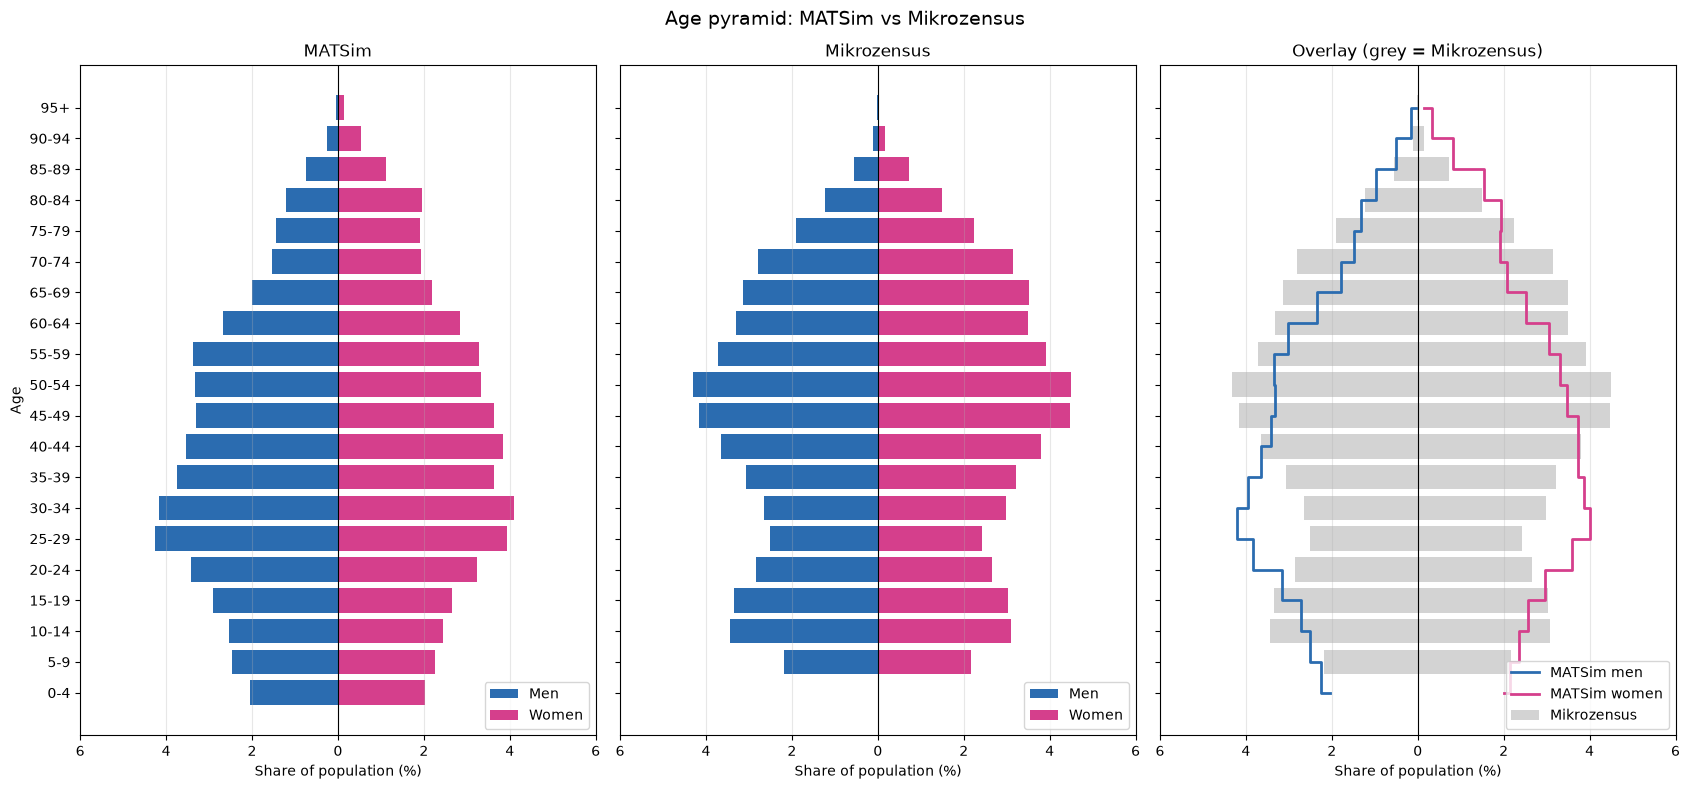

Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\validation


In [ ]:
""" Age pyramid: MATSim population vs Mikrozensus (zielpersonen.csv)
Run from the folder that contains Lausanne_10pct (adjust paths below if needed).
unweighted
"""
import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths
MATSIM_PATH = Path(r"working_rep\filterred_data\lausanne_population_filtered.xml.gz")
MZ_PATH = Path("Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus/zielpersonen.csv")
OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BIN_WIDTH = 5
MAX_AGE = 100
BINS = list(range(0, MAX_AGE + BIN_WIDTH, BIN_WIDTH))
LABELS = [f"{a}-{a + BIN_WIDTH - 1}" for a in BINS[:-2]] + [f"{BINS[-2]}+"]


# ------------------------------------------------------------------ MATSim
def read_matsim(path):
    """Returns DataFrame with columns age, sex ('m'/'f'). Handles attribute-style
    (<attributes><attribute name="age">) and old-style (<person age= sex=>) files."""
    rows = []
    person = None
    in_plan = False
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            tag = elem.tag
            if event == "start":
                if tag == "person":
                    person = {"age": elem.get("age"), "sex": elem.get("sex")}
                elif tag == "plan":
                    in_plan = True
            else:
                if tag == "attribute" and person is not None and not in_plan:
                    name = elem.get("name")
                    if name in ("age", "sex", "gender"):
                        person["sex" if name == "gender" else name] = (elem.text or "").strip()
                elif tag == "plan":
                    in_plan = False
                    elem.clear()
                elif tag == "person":
                    rows.append(person)
                    person = None
                    elem.clear()
    df = pd.DataFrame(rows)
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    df["sex"] = df["sex"].astype(str).str.lower().str[0].map({"m": "m", "f": "f"})
    n0 = len(df)
    df = df.dropna(subset=["age", "sex"])
    print(f"MATSim: {n0} persons, {len(df)} with valid age and sex")
    return df


# ------------------------------------------------------------------ Mikrozensus
def read_mz(path):
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, sep=None, engine="python",
                             usecols=["alter", "gesl"], encoding=enc)
            print(f"Mikrozensus read with encoding: {enc}")
            break
        except UnicodeDecodeError:
            continue
    df["age"] = pd.to_numeric(df["alter"], errors="coerce")
    df["sex"] = df["gesl"].map({1: "m", 2: "f"})
    n0 = len(df)
    df = df[df["age"] >= 0].dropna(subset=["age", "sex"])  # drop negative missing codes
    print(f"Mikrozensus: {n0} persons, {len(df)} with valid age and sex")
    return df[["age", "sex"]]


# ------------------------------------------------------------------ helpers
def shares(df):
    """% of total population per age bin and sex."""
    ages = df["age"].clip(upper=MAX_AGE)
    cut = pd.cut(ages, bins=BINS, right=False, labels=LABELS)
    tab = pd.crosstab(cut, df["sex"]).reindex(LABELS, fill_value=0)
    for s in ("m", "f"):
        if s not in tab:
            tab[s] = 0
    return tab[["m", "f"]] / len(df) * 100


def plot(mat, mz):
    y = np.arange(len(LABELS))
    xmax = max(mat.values.max(), mz.values.max()) * 1.1
    fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharey=True)

    for ax, tab, title in [(axes[0], mat, "MATSim"), (axes[1], mz, "Mikrozensus")]:
        ax.barh(y, -tab["m"], color="#2b6cb0", label="Men")
        ax.barh(y, tab["f"], color="#d53f8c", label="Women")
        ax.set_title(title)

    # overlay comparison
    ax = axes[2]
    ax.barh(y, -mz["m"], color="lightgrey", label="Mikrozensus")
    ax.barh(y, mz["f"], color="lightgrey")
    ax.step(-mat["m"], y, where="mid", color="#2b6cb0", lw=2, label="MATSim men")
    ax.step(mat["f"], y, where="mid", color="#d53f8c", lw=2, label="MATSim women")
    ax.set_title("Overlay (grey = Mikrozensus)")

    for ax in axes:
        ax.set_xlim(-xmax, xmax)
        ax.set_yticks(y)
        ax.set_yticklabels(LABELS)
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels([f"{abs(t):.0f}" for t in ax.get_xticks()])
        ax.set_xlabel("Share of population (%)")
        ax.axvline(0, color="black", lw=0.8)
        ax.grid(axis="x", alpha=0.3)
        ax.legend(loc="lower right")
    axes[0].set_ylabel("Age")
    fig.suptitle("Age pyramid: MATSim vs Mikrozensus", fontsize=14)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "age_pyramid_uw.png", dpi=200)
    plt.show()


# ------------------------------------------------------------------ main
if __name__ == "__main__":
    matsim = read_matsim(MATSIM_PATH)
    mz = read_mz(MZ_PATH)

    s_mat, s_mz = shares(matsim), shares(mz)

    out = pd.concat({"matsim_%": s_mat, "mikrozensus_%": s_mz}, axis=1)
    out.columns = [f"{a}_{b}" for a, b in out.columns]
    out["diff_m"] = out["matsim_%_m"] - out["mikrozensus_%_m"]
    out["diff_f"] = out["matsim_%_f"] - out["mikrozensus_%_f"]
    out.round(3).to_csv(OUT_DIR / "age_pyramid_table.csv")

    plot(s_mat, s_mz)
    print(f"Saved to {OUT_DIR.resolve()}")

Age pyramid - weighted - min age 6

MATSim: 34461 persons, 34461 with valid age and sex
Mikrozensus read with encoding: cp1252
Household filter: 57090 -> 1943 persons (1943 households)
Mikrozensus: 1943 persons, 1943 with valid age and sex


C:\Users\Sylvain\AppData\Local\Temp\ipykernel_5784\2911803340.py:137: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["age"] = pd.to_numeric(df["alter"], errors="coerce")
C:\Users\Sylvain\AppData\Local\Temp\ipykernel_5784\2911803340.py:138: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["sex"] = df["gesl"].map({1: "m", 2: "f"})
C:\Users\Sylvain\AppData\Local\Temp\ipykernel_5784\2911803340.py:140: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poo

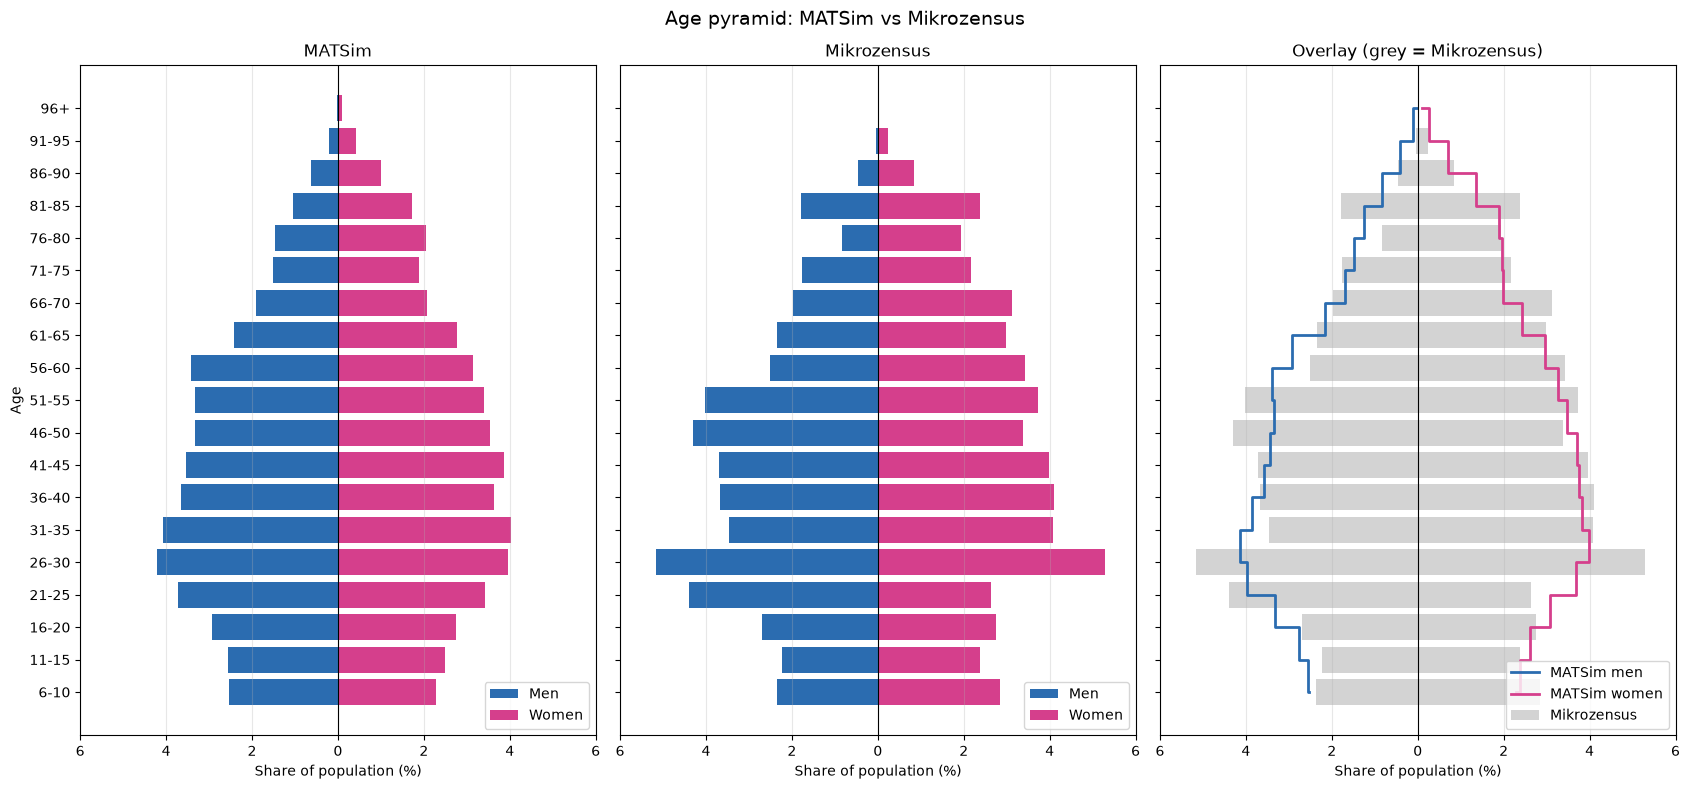

Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\validation


In [3]:
"""
Age pyramid: MATSim population vs Mikrozensus (zielpersonen.csv)

Purpose
-------
Validates the synthetic MATSim population against the Swiss Mikrozensus
(microcensus) by comparing their age/sex distributions.

Workflow
--------
1. Read the MATSim population (gzipped XML) -> age + sex per person.
2. Read the Mikrozensus target persons, keep only households located in the
   study area, and keep the survey weights (WP).
3. Compute the share (%) of the total population in each 5-year age bin,
   separately for men and women. MATSim is unweighted, Mikrozensus is weighted.
4. Save a comparison table (CSV) and a 3-panel pyramid plot (PNG):
   MATSim | Mikrozensus | overlay.

Run from the folder that contains Lausanne_10pct (adjust paths below if needed).
"""
import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths
# Input: filtered MATSim population (gzipped XML)
MATSIM_PATH = Path(r"working_rep\filterred_data\lausanne_population_filtered.xml.gz")
# Input: Mikrozensus target-person file (one row per surveyed person)
MZ_PATH = Path("Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus/zielpersonen.csv")
# Output folder for the table and the figure (created if missing)
OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Age binning: 5-year classes from 0 to 100, last class is open-ended ("100+")
MIN_AGE = 6       # minimum age of persons to include (set to 0 to keep everyone)
BIN_WIDTH = 5
MAX_AGE = 100     # the open-ended last bin starts at the last edge <= MAX_AGE
# Bin edges start at MIN_AGE, e.g. 6, 11, 16, ..., 96, then infinity to close the
# open-ended last bin (with MIN_AGE = 0 this gives 0, 5, ..., 100, inf).
BINS = list(range(MIN_AGE, MAX_AGE + 1, BIN_WIDTH)) + [np.inf]
# Labels like "6-10", "11-15", ... for all bins but the last, plus "96+"
# (or "100+" when MIN_AGE = 0) for the open-ended final bin.
LABELS = [f"{a}-{a + BIN_WIDTH - 1}" for a in BINS[:-2]] + [f"{BINS[-2]}+"]


# ------------------------------------------------------------------ MATSim
def read_matsim(path):
    """Returns DataFrame with columns age, sex ('m'/'f'). Handles attribute-style
    (<attributes><attribute name="age">) and old-style (<person age= sex=>) files."""
    rows = []          # one dict (age, sex) per person
    person = None      # the person currently being parsed
    in_plan = False    # True while inside a <plan>; used to ignore plan-level attributes

    # Stream-parse the file (iterparse) so large populations don't need to fit in memory
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            tag = elem.tag
            if event == "start":
                if tag == "person":
                    # Old-style format: age/sex are XML attributes of <person>.
                    # (They are None for the new attribute-style format.)
                    person = {"age": elem.get("age"), "sex": elem.get("sex")}
                elif tag == "plan":
                    in_plan = True
            else:  # event == "end": the element and its children are fully parsed
                if tag == "attribute" and person is not None and not in_plan:
                    # New-style format: <attribute name="age">42</attribute>
                    # Only person-level attributes are read (not those inside plans).
                    name = elem.get("name")
                    if name in ("age", "sex", "gender"):
                        # "gender" is treated as an alias for "sex"
                        person["sex" if name == "gender" else name] = (elem.text or "").strip()
                elif tag == "plan":
                    in_plan = False
                    elem.clear()   # free memory: plans are large and not needed
                elif tag == "person":
                    rows.append(person)
                    person = None
                    elem.clear()   # free memory

    df = pd.DataFrame(rows)
    # Convert age to a number; unparseable values become NaN
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    # Normalise sex to 'm'/'f' using the first letter (handles "male", "Female", "M", ...);
    # anything else becomes NaN
    df["sex"] = df["sex"].astype(str).str.lower().str[0].map({"m": "m", "f": "f"})
    n0 = len(df)
    # Drop persons without a valid age or sex
    df = df.dropna(subset=["age", "sex"])
    print(f"MATSim: {n0} persons, {len(df)} with valid age and sex")
    return df


# ------------------------------------------------------------------ Mikrozensus
def read_mz(path):
    """Reads the Mikrozensus person file, restricts it to households in the study
    area, and returns a DataFrame with columns age, sex ('m'/'f') and weight."""
    # Try several encodings, since the file may not be UTF-8 (typical for Swiss
    # data exports). sep=None with the python engine lets pandas auto-detect the
    # delimiter (comma, semicolon, tab, ...).
    # NOTE: if all three encodings fail, `df` is never defined; latin-1 can decode
    # any byte sequence, so in practice the last attempt always succeeds.
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(
                path,
                sep=None,
                engine="python",
                encoding=enc
            )
            print(f"Mikrozensus read with encoding: {enc}")
            break
        except UnicodeDecodeError:
            continue

    # -------------------------------------------------- filter households
    # Keep only persons whose household (HHNR) lies inside the study area.
    # The list of household IDs was produced in an earlier filtering step.
    hh_file = Path(r"working_rep/filterred_data/mz/household_ids_in_area.csv")

    hh_ids = pd.read_csv(hh_file)["HHNR"].unique()

    n_before = len(df)
    df = df[df["HHNR"].isin(hh_ids)]
    print(
        f"Household filter: {n_before} -> {len(df)} persons "
        f"({df['HHNR'].nunique()} households)"
    )

    # -------------------------------------------------- age / sex
    # Column names follow the Mikrozensus codebook:
    #   alter = age in years, gesl = sex (1 = male, 2 = female), WP = person weight
    df["age"] = pd.to_numeric(df["alter"], errors="coerce")
    df["sex"] = df["gesl"].map({1: "m", 2: "f"})
    # Missing weights are set to 0 so those persons don't contribute to the totals
    df["weight"] = pd.to_numeric(df["WP"], errors="coerce").fillna(0)

    n0 = len(df)
    # Remove invalid ages (negative values are typically "no answer" codes)
    # and rows with missing age or sex
    df = df[df["age"] >= 0].dropna(subset=["age", "sex"])

    print(f"Mikrozensus: {n0} persons, {len(df)} with valid age and sex")

    return df[["age", "sex", "weight"]]


# ------------------------------------------------------------------ helpers
def shares(df, weight_col=None):
    """% of total population per age bin and sex.

    Returns a DataFrame indexed by age-bin label with columns 'm' and 'f'.
    Values are percentages of the *total* population (men + women), so the
    sum over all cells equals 100. If weight_col is given, the weights are
    summed instead of counting persons."""

    # Ages above MAX_AGE are put into the last open-ended bin ("100+")
    ages = df["age"].clip(upper=MAX_AGE)
    # right=False -> bins are [0,5), [5,10), ... (left-inclusive)
    bins = pd.cut(ages, bins=BINS, right=False, labels=LABELS)

    if weight_col is None:
        # Unweighted: simple head count per (age bin, sex)
        tab = pd.crosstab(bins, df["sex"])
        total = len(df)
    else:
        # Weighted: sum of survey weights per (age bin, sex)
        tmp = pd.DataFrame({
            "age_bin": bins,
            "sex": df["sex"],
            "weight": df[weight_col]
        })

        tab = pd.pivot_table(
            tmp,
            index="age_bin",
            columns="sex",
            values="weight",
            aggfunc="sum",
            fill_value=0,
            observed=False,   # keep empty bins as well
        )

        total = tmp["weight"].sum()

    # Make sure all age bins are present and in the right order
    tab = tab.reindex(LABELS, fill_value=0)

    # Guard against a sex being completely absent from the data
    for s in ("m", "f"):
        if s not in tab:
            tab[s] = 0

    # Convert counts/weights to percentages of the total population
    return tab[["m", "f"]] / total * 100


def plot(mat, mz):
    """Draws three side-by-side panels sharing the same age axis:
    (1) MATSim pyramid, (2) Mikrozensus pyramid, (3) overlay of both."""
    y = np.arange(len(LABELS))  # one y position per age bin
    # Common x-limit (+10% margin) so all panels are directly comparable
    xmax = max(mat.values.max(), mz.values.max()) * 1.1
    fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharey=True)

    # Panels 1 and 2: classic pyramids. Men are plotted as negative values
    # (extending left), women as positive values (extending right).
    for ax, tab, title in [(axes[0], mat, "MATSim"), (axes[1], mz, "Mikrozensus")]:
        ax.barh(y, -tab["m"], color="#2b6cb0", label="Men")
        ax.barh(y, tab["f"], color="#d53f8c", label="Women")
        ax.set_title(title)

    # Panel 3 - overlay: Mikrozensus as grey bars (reference),
    # MATSim as coloured step lines on top, so deviations are easy to spot
    ax = axes[2]
    ax.barh(y, -mz["m"], color="lightgrey", label="Mikrozensus")
    ax.barh(y, mz["f"], color="lightgrey")
    ax.step(-mat["m"], y, where="mid", color="#2b6cb0", lw=2, label="MATSim men")
    ax.step(mat["f"], y, where="mid", color="#d53f8c", lw=2, label="MATSim women")
    ax.set_title("Overlay (grey = Mikrozensus)")

    # Formatting shared by all three panels
    for ax in axes:
        ax.set_xlim(-xmax, xmax)
        ax.set_yticks(y)
        ax.set_yticklabels(LABELS)
        # Fix the tick positions, then relabel them with absolute values
        # (the left side is stored as negative numbers but should read as positive %)
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels([f"{abs(t):.0f}" for t in ax.get_xticks()])
        ax.set_xlabel("Share of population (%)")
        ax.axvline(0, color="black", lw=0.8)  # centre line between men and women
        ax.grid(axis="x", alpha=0.3)
        ax.legend(loc="lower right")
    axes[0].set_ylabel("Age")
    fig.suptitle("Age pyramid: MATSim vs Mikrozensus", fontsize=14)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "age_pyramid_w.png", dpi=200)
    plt.show()


# ------------------------------------------------------------------ main
if __name__ == "__main__":
    matsim = read_matsim(MATSIM_PATH)
    mz = read_mz(MZ_PATH)

    s_mat = shares(matsim)                 # unweighted MATSim (each agent counts as 1)
    s_mz  = shares(mz, weight_col="weight")  # weighted Mikrozensus (survey weights WP)

    # Build a comparison table: one column per (source, sex), e.g. matsim_%_m
    out = pd.concat({"matsim_%": s_mat, "mikrozensus_%": s_mz}, axis=1)
    out.columns = [f"{a}_{b}" for a, b in out.columns]  # flatten the MultiIndex
    # Differences in percentage points (positive = MATSim over-represents the group)
    out["diff_m"] = out["matsim_%_m"] - out["mikrozensus_%_m"]
    out["diff_f"] = out["matsim_%_f"] - out["mikrozensus_%_f"]
    out.round(3).to_csv(OUT_DIR / "age_pyramid_table.csv")

    plot(s_mat, s_mz)
    print(f"Saved to {OUT_DIR.resolve()}")

Age distribution representation bins = 1 year

MATSim: 34461 persons, 34461 with valid age
Mikrozensus read with encoding: cp1252
Mikrozensus: 1943 persons, 1943 with valid age
Age axis: 6 to 103 (98 bins)


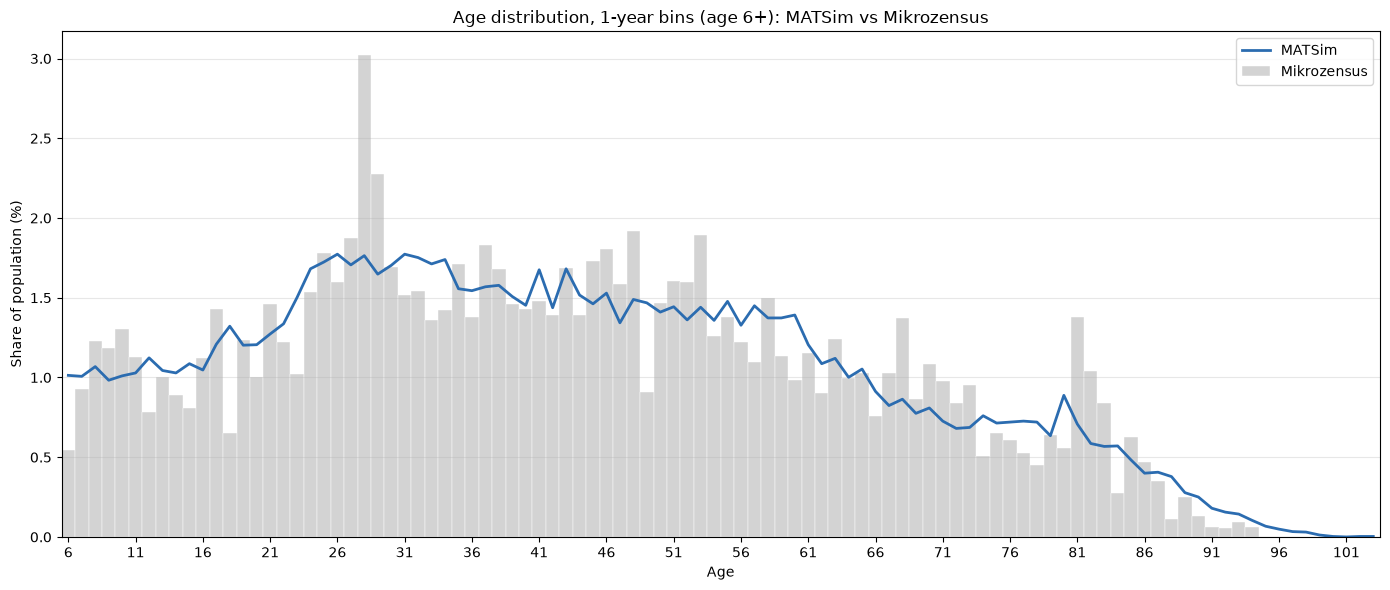

Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\validation


In [10]:
"""
Age distribution (1-year bins, from MIN_AGE to the maximum age found):
Mikrozensus (weighted) as full bars, MATSim (unweighted) as a curve on top.

Uses the same inputs and the same reading logic as the age pyramid script.
Shares are % of all persons aged >= MIN_AGE (men + women), so each source sums to 100.
"""
import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths
MATSIM_PATH = Path(r"working_rep\filterred_data\lausanne_population_filtered.xml.gz")
MZ_PATH = Path("Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus/zielpersonen.csv")
HH_FILE = Path(r"working_rep/filterred_data/mz/household_ids_in_area.csv")
OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_AGE = 6
HORIZONTAL = False  # True: age on the y-axis, horizontal bars, curve to the right of them
                    # False: age on the x-axis, vertical bars, curve above them


# ------------------------------------------------------------------ MATSim
def read_matsim(path):
    rows, person, in_plan = [], None, False
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            tag = elem.tag
            if event == "start":
                if tag == "person":
                    person = {"age": elem.get("age")}
                elif tag == "plan":
                    in_plan = True
            else:
                if tag == "attribute" and person is not None and not in_plan:
                    if elem.get("name") == "age":
                        person["age"] = (elem.text or "").strip()
                elif tag == "plan":
                    in_plan = False
                    elem.clear()
                elif tag == "person":
                    rows.append(person)
                    person = None
                    elem.clear()
    df = pd.DataFrame(rows)
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    n0 = len(df)
    df = df.dropna(subset=["age"])
    print(f"MATSim: {n0} persons, {len(df)} with valid age")
    return df


# ------------------------------------------------------------------ Mikrozensus
def read_mz(path):
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, sep=None, engine="python", encoding=enc)
            print(f"Mikrozensus read with encoding: {enc}")
            break
        except UnicodeDecodeError:
            continue

    hh_ids = pd.read_csv(HH_FILE)["HHNR"].unique()
    df = df[df["HHNR"].isin(hh_ids)].copy()

    df["age"] = pd.to_numeric(df["alter"], errors="coerce")
    df["weight"] = pd.to_numeric(df["WP"], errors="coerce").fillna(0)
    n0 = len(df)
    df = df[df["age"] >= 0].dropna(subset=["age"])
    print(f"Mikrozensus: {n0} persons, {len(df)} with valid age")
    return df[["age", "weight"]]


# ------------------------------------------------------------------ helpers
def shares_1y(ages, ages_axis, weights=None):
    """% of persons per single year of age (floor of age), on a fixed age axis."""
    a = np.floor(ages).astype(int)
    w = np.ones(len(a)) if weights is None else np.asarray(weights, dtype=float)
    s = pd.Series(w, index=a).groupby(level=0).sum()
    s = s.reindex(ages_axis, fill_value=0)
    return s / s.sum() * 100


def plot(ages_axis, mz_share, mat_share):
    fig, ax = plt.subplots(figsize=(8, 12) if HORIZONTAL else (14, 6))

    if HORIZONTAL:
        ax.barh(ages_axis, mz_share.values, height=1.0, color="lightgrey",
                edgecolor="white", linewidth=0.3, label="Mikrozensus")
        ax.plot(mat_share.values, ages_axis, color="#2b6cb0", lw=2, label="MATSim")
        ax.set_xlabel("Share of population (%)")
        ax.set_ylabel("Age")
        ax.set_ylim(ages_axis[0] - 0.5, ages_axis[-1] + 0.5)
        ax.set_yticks(range(ages_axis[0], ages_axis[-1] + 1, 5))
        ax.grid(axis="x", alpha=0.3)
    else:
        ax.bar(ages_axis, mz_share.values, width=1.0, color="lightgrey",
               edgecolor="white", linewidth=0.3, label="Mikrozensus")
        ax.plot(ages_axis, mat_share.values, color="#2b6cb0", lw=2, label="MATSim")
        ax.set_xlabel("Age")
        ax.set_ylabel("Share of population (%)")
        ax.set_xlim(ages_axis[0] - 0.5, ages_axis[-1] + 0.5)
        ax.set_xticks(range(ages_axis[0], ages_axis[-1] + 1, 5))
        ax.grid(axis="y", alpha=0.3)

    ax.legend()
    ax.set_title(f"Age distribution, 1-year bins (age {ages_axis[0]}+): MATSim vs Mikrozensus")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "age_distribution_1y.png", dpi=200)
    plt.show()


# ------------------------------------------------------------------ main
if __name__ == "__main__":
    matsim = read_matsim(MATSIM_PATH)
    mz = read_mz(MZ_PATH)

    matsim = matsim[matsim["age"] >= MIN_AGE]
    mz = mz[mz["age"] >= MIN_AGE]

    max_age = int(np.floor(max(matsim["age"].max(), mz["age"].max())))
    ages_axis = list(range(MIN_AGE, max_age + 1))
    print(f"Age axis: {MIN_AGE} to {max_age} ({len(ages_axis)} bins)")

    s_mat = shares_1y(matsim["age"], ages_axis)
    s_mz = shares_1y(mz["age"], ages_axis, weights=mz["weight"])

    out = pd.DataFrame({"matsim_%": s_mat, "mikrozensus_%": s_mz})
    out["diff"] = out["matsim_%"] - out["mikrozensus_%"]
    out.index.name = "age"
    out.round(4).to_csv(OUT_DIR / "age_distribution_1y_table.csv")

    plot(ages_axis, s_mz, s_mat)
    print(f"Saved to {OUT_DIR.resolve()}")

Driving licence comparaison


MATSim: 34,461 persons with licence info, 32,766 aged >= 6

MZ household filter: 57,090 -> 1,943 persons
MZ: 1,943 persons -> 1,943 with licence info and aged >= 6

MATSim %
hasLicense
yes    70.353415
no     29.646585
Name: weight, dtype: float64

Mikrozensus weighted %
hasLicense
yes    67.925107
no     32.074893
Name: weight, dtype: float64


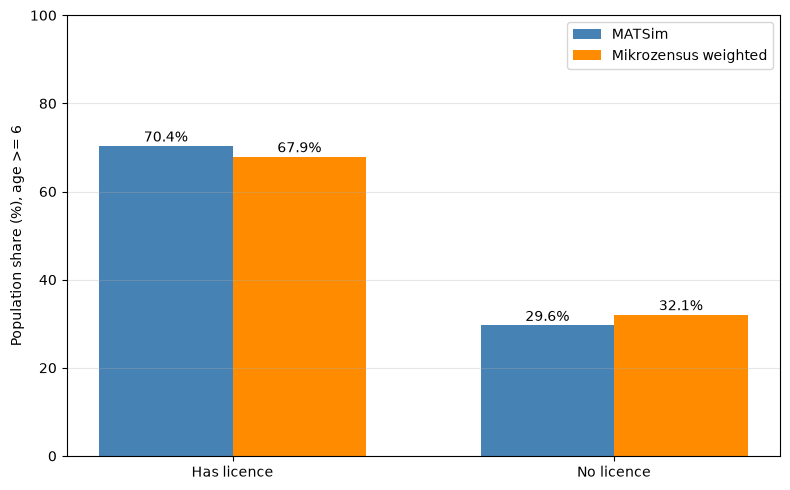

In [8]:
"""
Driving-licence validation: MATSim synthetic population vs. Mikrozensus (MZ).

Compares the share of persons with / without a driving licence in the
MATSim population and in the (weighted) Mikrozensus, restricted to
persons aged MIN_AGE and above.
"""

import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ settings

MATSIM_PATH = Path("working_rep/filterred_data/lausanne_population_filtered.xml.gz")
MZ_PATH = Path(r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\zielpersonen.csv")
HH_PATH = Path("working_rep/filterred_data/mz/household_ids_in_area.csv")  # households inside study area

OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_AGE = 6  # only persons of this age or older are considered
CATEGORIES = ["yes", "no"]  # order used for shares and plot


# ------------------------------------------------------------------ MATSim

def read_matsim(path):
    """Read the MATSim population (gzipped XML).

    Returns a DataFrame with columns: age, hasLicense ('yes'/'no'), weight (=1).
    Only person-level attributes are read; attributes inside <plan> are ignored.
    """
    rows = []          # one dict per person
    person = None      # person currently being parsed
    in_plan = False    # True while inside a <plan> (plan attributes are skipped)

    # Stream-parse so large populations don't have to fit in memory
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            tag = elem.tag

            if event == "start":
                if tag == "person":
                    # Old-style files store age as an XML attribute of <person>
                    # (None for attribute-style files, overwritten below)
                    person = {"age": elem.get("age")}
                elif tag == "plan":
                    in_plan = True

            else:  # "end": element and its children are fully parsed
                if tag == "attribute" and person is not None and not in_plan:
                    # New-style files: <attribute name="age">42</attribute>
                    name = elem.get("name")
                    if name in ("age", "hasLicense"):
                        person[name] = (elem.text or "").strip().lower()
                elif tag == "plan":
                    in_plan = False
                elif tag == "person":
                    # Keep only persons for which a licence status is known
                    if "hasLicense" in person:
                        rows.append(person)
                    person = None
                    elem.clear()  # free memory

    df = pd.DataFrame(rows)
    df["age"] = pd.to_numeric(df["age"], errors="coerce")  # invalid -> NaN
    df["weight"] = 1.0                                     # every agent counts once

    n0 = len(df)
    df = df[df["age"] >= MIN_AGE]  # also drops NaN ages (comparison is False)
    print(f"\nMATSim: {n0:,} persons with licence info, {len(df):,} aged >= {MIN_AGE}")

    return df


# ------------------------------------------------------------------ Mikrozensus

def read_mz(path):
    """Read the MZ person file, keep persons in the study area aged >= MIN_AGE.

    Returns a DataFrame with columns: age, hasLicense ('yes'/'no'), weight.
    Codebook: alter = age, f20400a = licence (1 = yes, 2 = no), WP = person weight.
    """
    # Swiss exports are often not UTF-8, so try several encodings.
    # sep=None lets pandas auto-detect the delimiter. latin-1 decodes any bytes,
    # so the last attempt always succeeds.
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, sep=None, engine="python", encoding=enc)
            break
        except UnicodeDecodeError:
            continue

    # Keep only households inside the study area
    hh_ids = pd.read_csv(HH_PATH)["HHNR"].unique()
    n0 = len(df)
    df = df[df["HHNR"].isin(hh_ids)].copy()
    print(f"\nMZ household filter: {n0:,} -> {len(df):,} persons")

    # Convert codes to usable values (invalid entries become NaN)
    df["age"] = pd.to_numeric(df["alter"], errors="coerce")
    df["hasLicense"] = pd.to_numeric(df["f20400a"], errors="coerce").map({1: "yes", 2: "no", -99: "no"})
    df["weight"] = pd.to_numeric(df["WP"], errors="coerce").fillna(0)  # missing weight -> no contribution

    # Drop unknown licence status and apply the age filter (also removes NaN / negative ages)
    n0 = len(df)
    df = df.dropna(subset=["hasLicense"])
    df = df[df["age"] >= MIN_AGE]
    print(f"MZ: {n0:,} persons -> {len(df):,} with licence info and aged >= {MIN_AGE}")

    return df[["age", "hasLicense", "weight"]]


# ------------------------------------------------------------------ shares

def licence_share(df):
    """Weighted share (%) of 'yes' / 'no'. MATSim has weight 1, so it is a plain count."""
    totals = df.groupby("hasLicense")["weight"].sum().reindex(CATEGORIES, fill_value=0)
    return totals / totals.sum() * 100


# ------------------------------------------------------------------ plot

def plot(matsim_share, mz_share):
    """Grouped bar chart of MATSim vs. weighted MZ shares, saved to OUT_DIR."""
    labels = ["Has licence", "No licence"]
    x = np.arange(len(labels))
    width = 0.35

    fig, ax = plt.subplots(figsize=(8, 5))

    # One bar group per source, offset left/right of each tick
    for offset, share, label, color in [
        (-width / 2, matsim_share, "MATSim", "steelblue"),
        (+width / 2, mz_share, "Mikrozensus weighted", "darkorange"),
    ]:
        values = share[CATEGORIES].values
        ax.bar(x + offset, values, width, label=label, color=color)
        for xi, v in zip(x + offset, values):
            ax.text(xi, v + 1, f"{v:.1f}%", ha="center")  # value label above bar

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel(f"Population share (%), age >= {MIN_AGE}")
    ax.set_ylim(0, 100)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.savefig(OUT_DIR / "driving_licence_validation.png", dpi=300)
    plt.show()


# ------------------------------------------------------------------ main

if __name__ == "__main__":
    matsim_share = licence_share(read_matsim(MATSIM_PATH))
    mz_share = licence_share(read_mz(MZ_PATH))

    print("\nMATSim %")
    print(matsim_share)
    print("\nMikrozensus weighted %")
    print(mz_share)

    plot(matsim_share, mz_share)

household municipality type comparaison

MATSim: 15987 households
MATSim municipalityType values found:
municipalityType
urban        7745
urbancore    7023
suburban     1219
Mikrozensus households read with encoding: cp1252
Household filter: 57090 -> 1943 households in the area
          matsim_n  mikrozensus_n_unweighted  matsim_%  mikrozensus_%  diff_pp
type                                                                          
urban        14768                      1348     92.38          73.99    18.38
suburban      1219                       489      7.62          22.20   -14.58
rural            0                       106      0.00           3.81    -3.81
unknown          0                         0      0.00           0.00     0.00


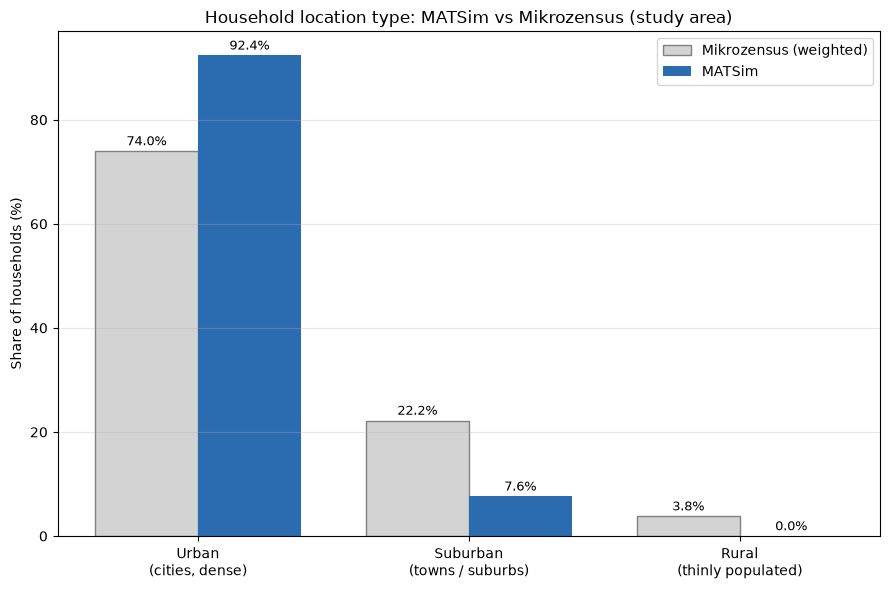

Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\validation


In [15]:
"""
Household location type (urban / suburban / rural): MATSim vs Mikrozensus.

MATSim : lausanne_households_filtered.xml.gz -> <attribute name="municipalityType">
Mikrozensus: Haushalte.csv -> W_DEGURBA (DEGURBA classification),
             restricted to households in the study area (household_ids_in_area.csv),
             weighted by the household weight.

Shares are % of households (weighted for the Mikrozensus, unweighted for MATSim).
"""
import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths
MATSIM_HH_PATH = Path(r"working_rep\filterred_data\lausanne_households_filtered.xml.gz")
MZ_HH_PATH = Path("Lausanne_10pct/Lausanne_10pct/Mikrozensus/microcensus/Haushalte.csv")
HH_FILE = Path(r"working_rep/filterred_data/mz/household_ids_in_area.csv")
OUT_DIR = Path("working_rep/validation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Household weight column in Haushalte.csv. If it is not found, the script lists the
# available columns and falls back to unweighted counts (check the codebook!).
WEIGHT_COL = "WM"
EXCLUDE_UNKNOWN = False   # True: drop "unknown" households before computing shares

# ------------------------------------------------------------------ categories
CATS = ["urban", "suburban", "rural", "unknown"]
LABELS = {
    "urban": "Urban\n(cities, dense)",
    "suburban": "Suburban\n(towns / suburbs)",
    "rural": "Rural\n(thinly populated)",
    "unknown": "Unknown /\nmissing",
}
# Mikrozensus W_DEGURBA codes
MZ_MAP = {1: "urban", 2: "suburban", 3: "rural", -97: "unknown"}
# MATSim municipalityType strings (lower-cased); anything unlisted is reported and
# counted as "unknown" so nothing silently disappears.
MATSIM_MAP = {
    "urban": "urban", "urbancore": "urban", "cities": "urban",
    "suburban": "suburban", "intermediate": "suburban", "town": "suburban",
    "towns": "suburban", "semi-urban": "suburban", "semiurban": "suburban",
    "rural": "rural",
}



# ------------------------------------------------------------------ MATSim
def read_matsim_households(path):
    """One row per household with its municipalityType (raw string)."""
    rows, hh = [], None
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("start", "end")):
            # households files usually declare an XML namespace, which turns the tag
            # into "{http://...}household" -> strip it
            tag = elem.tag.rsplit("}", 1)[-1]
            if event == "start":
                if tag == "household":
                    hh = {"id": elem.get("id"), "municipalityType": None}
            else:
                if tag == "attribute" and hh is not None:
                    if elem.get("name") == "municipalityType":
                        hh["municipalityType"] = (elem.text or "").strip()
                elif tag == "household":
                    rows.append(hh)
                    hh = None
                    elem.clear()
    df = pd.DataFrame(rows, columns=["id", "municipalityType"])
    if df.empty:
        raise ValueError("No <household> elements found in the MATSim file - "
                         "check MATSIM_HH_PATH / the XML structure.")
    print(f"MATSim: {len(df)} households")
    print("MATSim municipalityType values found:")
    print(df["municipalityType"].fillna("<missing>").value_counts().to_string())

    raw = df["municipalityType"].fillna("").str.lower()
    df["cat"] = raw.map(MATSIM_MAP).fillna("unknown")
    unmapped = sorted(set(raw) - set(MATSIM_MAP) - {""})
    if unmapped:
        print(f"WARNING: unmapped MATSim values counted as 'unknown': {unmapped}")
    return df


# ------------------------------------------------------------------ Mikrozensus
def read_mz_households(path):
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, sep=None, engine="python", encoding=enc)
            print(f"Mikrozensus households read with encoding: {enc}")
            break
        except UnicodeDecodeError:
            continue

    # keep only households inside the study area
    hh_ids = pd.read_csv(HH_FILE)["HHNR"].unique()
    n_before = len(df)
    df = df[df["HHNR"].isin(hh_ids)].copy()
    print(f"Household filter: {n_before} -> {len(df)} households in the area")

    df["cat"] = pd.to_numeric(df["W_DEGURBA"], errors="coerce").map(MZ_MAP).fillna("unknown")

    if WEIGHT_COL in df.columns:
        df["weight"] = pd.to_numeric(df[WEIGHT_COL], errors="coerce").fillna(0)
    else:
        print(f"WARNING: weight column '{WEIGHT_COL}' not found -> unweighted. "
              f"Columns: {list(df.columns)}")
        df["weight"] = 1.0
    return df[["HHNR", "cat", "weight"]]


# ------------------------------------------------------------------ helpers
def shares(cats, weights=None):
    w = np.ones(len(cats)) if weights is None else np.asarray(weights, dtype=float)
    s = pd.Series(w, index=cats.values).groupby(level=0).sum().reindex(CATS, fill_value=0)
    if EXCLUDE_UNKNOWN:
        s["unknown"] = 0
    return s / s.sum() * 100


def plot(mat, mz):
    cats = [c for c in CATS if not (c == "unknown" and mat[c] == 0 and mz[c] == 0)]
    x = np.arange(len(cats))
    w = 0.38
    fig, ax = plt.subplots(figsize=(9, 6))
    b1 = ax.bar(x - w / 2, [mz[c] for c in cats], w, color="lightgrey",
                edgecolor="grey", label="Mikrozensus (weighted)")
    b2 = ax.bar(x + w / 2, [mat[c] for c in cats], w, color="#2b6cb0", label="MATSim")
    for bars in (b1, b2):
        ax.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS[c] for c in cats])
    ax.set_ylabel("Share of households (%)")
    ax.set_title("Household location type: MATSim vs Mikrozensus (study area)")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT_DIR / "household_urbanity.png", dpi=200)
    plt.show()


# ------------------------------------------------------------------ main
if __name__ == "__main__":
    matsim = read_matsim_households(MATSIM_HH_PATH)
    mz = read_mz_households(MZ_HH_PATH)

    s_mat = shares(matsim["cat"])
    s_mz = shares(mz["cat"], weights=mz["weight"])

    out = pd.DataFrame({
        "matsim_n": matsim["cat"].value_counts().reindex(CATS, fill_value=0),
        "mikrozensus_n_unweighted": mz["cat"].value_counts().reindex(CATS, fill_value=0),
        "matsim_%": s_mat,
        "mikrozensus_%": s_mz,
    })
    out["diff_pp"] = out["matsim_%"] - out["mikrozensus_%"]
    out.index.name = "type"
    print(out.round(2).to_string())
    out.round(3).to_csv(OUT_DIR / "household_urbanity_table.csv")

    plot(s_mat, s_mz)
    print(f"Saved to {OUT_DIR.resolve()}")

activity chains comparaison - filtered based household adress in canton vaud - only basic activity chains (work shop education leisure)

In [22]:
"""
Compare activity-chain (tour) shares between a MATSim population and the
Swiss Microcensus (MZ) for the Lausanne study area.

A "chain" is a home-based tour written as a string of one-letter activity codes,
e.g. "HWH" = home -> work -> home, "HWSH" = home -> work -> shop -> home.

    H  home          W  work         E  education
    S  shop          L  leisure      O  other
    Ou activity outside the study area

Persons/households that never leave home are counted as the chain "H".

Output: chain_comparison.csv with counts and shares for both sources and the
difference in percentage points.
"""

import gzip
import re
import xml.etree.ElementTree as ET
from collections import Counter

import geopandas as gpd
import pandas as pd
import shapely

# =============================================================================
# CONFIGURATION
# =============================================================================

# ---- input / output paths ---------------------------------------------------
MATSIM_PLANS = r"working_rep\filterred_data\lausanne_population_filtered_age6plus.xml.gz"
MZ_TRIPS = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\wege.csv"
MZ_PERSONS = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\zielpersonen.csv"
MZ_HOUSEHOLDS_IN_AREA = r"working_rep\filterred_data\mz\household_ids_in_area.csv"
BOUNDARY_SHP = (r"C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\Lausanne_10pct"
                r"\Lausanne_10pct\Boundary\LausanneExtent.shp")
OUTPUT_CSV = "chain_comparison.csv"

# ---- microcensus column names (all lower case, see read_csv_clean) ----------
HH_COL = "hhnr"          # household id (used as the "person" key throughout)
ORDER_COL = "f51100"     # trip order within the day (negative = invalid)
PURPOSE_COL = "wzweck1"  # trip purpose code of the trip's destination
WEIGHT_COL = "wp"        # person weight
OUTING_COL = "ausnr"     # outing id (a home-to-home excursion)
DEST_X_COL = "z_x"       # destination longitude (WGS84)
DEST_Y_COL = "z_y"       # destination latitude  (WGS84)

# ---- survey-day filter (columns of zielpersonen.csv) ------------------------
DAY_COL = "tag"                # 1 = Monday ... 7 = Sunday
KEEP_DAYS = {1, 2, 3, 4, 5}    # weekdays only

# ---- optional age filter on the MZ side -------------------------------------
AGE_COL = None   # e.g. "alter"; None disables the filter
MIN_AGE = 6

# ---- MZ purpose code -> chain letter ----------------------------------------
MZ_HOME = 11
MZ_MAP = {
    1: "O", 2: "W", 3: "E", 4: "S", 5: "O", 6: "W",
    7: "O", 8: "L", 9: "O", 10: "O", 12: "O", 13: "O",
}

# ---- MATSim activity type -> chain letter -----------------------------------
MATSIM_HOME = "home"
MATSIM_MAP = {
    "work": "W", "education": "E", "shop": "S", "leisure": "L",
    "other": "O", "outside": "Ou",
    "work_secondary": "W", "education_secondary": "E",
    "home_secondary": "O",   # judgment call: secondary homes count as "other"
}

# ---- how tours are built ----------------------------------------------------
# MZ: build one tour per outing (True) or per household-day (False)
USE_OUTINGS = True
# MZ (only if USE_OUTINGS is False): merge consecutive trips with the same purpose
COLLAPSE_RETURN_PAIRS = True
# MATSim: how to treat plans that do not start and end at home
#   "drop"   - keep only the complete H...H tours inside the plan
#   "cyclic" - rotate the plan so it starts at the first home, then close it
#   "insert" - add a home at the start and/or end
CLOSE_MODE = "drop"


# =============================================================================
# CHAIN HELPERS (shared by MATSim and MZ)
# =============================================================================

def merge_outside(chain: str) -> str:
    """Collapse consecutive 'Ou' stops into one: HOuOuOuH -> HOuH."""
    return re.sub(r"(?:Ou)+", "Ou", chain)


def split_into_tours(codes: list[str]) -> list[str]:
    """
    Cut a sequence of letters at every 'H' and return the complete
    home-to-home tours. Anything before the first H or after the last H
    is discarded (it is not a closed tour).

    ["H", "W", "H", "S", "L", "H"] -> ["HWH", "HSLH"]
    """
    tours, current, started = [], [], False
    for code in codes:
        if code == "H":
            if started and current:          # a tour just closed
                tours.append("H" + "".join(current) + "H")
            current, started = [], True      # this H also opens the next tour
        elif started:
            current.append(code)
    return tours


def plan_tours(seq: list[str], mode: str) -> tuple[list[str], str]:
    """
    Turn one daily activity sequence into tours.

    Returns (tours, status) where status is
        'home'     - only home activities (or nothing): person stays home
        'excluded' - no usable tour could be built (no home anchor at all)
        'ok'       - plan was already complete (or yielded tours in 'drop' mode)
        'closed'   - plan was repaired according to `mode`
    """
    if all(c == "H" for c in seq):
        return [], "home"
    if "H" not in seq:
        return [], "excluded"

    # Plan already starts and ends at home: nothing to repair
    if seq[0] == "H" and seq[-1] == "H":
        return split_into_tours(seq), "ok"

    if mode == "drop":
        tours = split_into_tours(seq)
        return tours, ("ok" if tours else "excluded")

    if mode == "cyclic":
        first_home = seq.index("H")
        seq = seq[first_home:] + seq[:first_home] + ["H"]
    else:  # "insert"
        if seq[0] != "H":
            seq = ["H"] + seq
        if seq[-1] != "H":
            seq = seq + ["H"]
    return split_into_tours(seq), "closed"


# =============================================================================
# MATSIM
# =============================================================================

def matsim_chains() -> Counter:
    """Count tours (and stay-at-home persons as 'H') in the MATSim plans file."""
    status_counts = Counter()   # how each person's plan was handled
    chains = Counter()          # chain string -> number of occurrences
    n_persons = 0

    with gzip.open(MATSIM_PLANS, "rb") as f:
        # Stream the XML so the whole population never sits in memory
        for _, el in ET.iterparse(f, events=("end",)):
            if el.tag != "person":
                continue
            n_persons += 1

            # Use the selected plan, falling back to the first one
            plans = el.findall("plan")
            plan = next((p for p in plans if p.get("selected") == "yes"),
                        plans[0] if plans else None)

            tours, status = [], "home"
            if plan is not None and plan.find("leg") is not None:
                # Translate activity types to letters; unknown types are skipped
                seq = []
                for act in plan.findall("activity"):
                    act_type = act.get("type", "")
                    if act_type == MATSIM_HOME:
                        seq.append("H")
                    elif act_type in MATSIM_MAP:
                        seq.append(MATSIM_MAP[act_type])
                tours, status = plan_tours(seq, CLOSE_MODE)
                tours = [merge_outside(t) for t in tours]

            status_counts[status] += 1
            if tours:
                chains.update(tours)
            elif status == "home":
                chains["H"] += 1
            # 'excluded' persons are not counted anywhere

            el.clear()  # free memory

    print(f"MATSim: {n_persons} persons, {sum(chains.values())} tours (incl. H), "
          f"H persons: {chains['H']}")
    print(dict(status_counts))
    return chains


# =============================================================================
# MICROCENSUS
# =============================================================================

def read_csv_clean(path: str) -> pd.DataFrame:
    """
    Read a CSV whose encoding and separator are unknown.
    Tries several encodings; for each, picks the separator that yields the most
    columns. Column names are stripped and lower-cased.
    """
    for encoding in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            candidates = [pd.read_csv(path, sep=sep, encoding=encoding, low_memory=False)
                          for sep in (",", ";", "\t")]
        except UnicodeDecodeError:
            continue  # wrong encoding, try the next one
        df = max(candidates, key=lambda d: d.shape[1])
        df.columns = [str(c).strip().lower() for c in df.columns]
        return df
    raise ValueError(f"Could not decode {path} with any known encoding")


def require_columns(df: pd.DataFrame, cols: list[str], name: str) -> None:
    """Exit with a helpful message if expected columns are missing."""
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise SystemExit(f"Missing columns {missing} in {name}. "
                         f"Available: {list(df.columns)}")


def inside_area_mask(df: pd.DataFrame, x_col: str, y_col: str) -> pd.Series:
    """True for rows whose (x, y) point lies inside the study-area boundary."""
    area = gpd.read_file(BOUNDARY_SHP)
    print("boundary CRS:", area.crs)
    area = area.to_crs(epsg=4326)  # MZ coordinates are WGS84
    # union_all() replaces the deprecated unary_union in newer geopandas
    polygon = (area.geometry.union_all() if hasattr(area.geometry, "union_all")
               else area.unary_union)

    x = pd.to_numeric(df[x_col], errors="coerce")
    y = pd.to_numeric(df[y_col], errors="coerce")
    valid = x.notna() & y.notna()

    mask = pd.Series(False, index=df.index)
    mask[valid] = shapely.contains_xy(polygon, x[valid].to_numpy(), y[valid].to_numpy())
    print(f"trips with missing/invalid destination coords: {(~valid).sum()}")
    return mask


def load_area_households() -> set:
    """Household ids that lie in the study area."""
    hh = read_csv_clean(MZ_HOUSEHOLDS_IN_AREA)
    if HH_COL in hh.columns:
        ids = hh[HH_COL]
    elif hh.shape[1] == 1:          # headerless single-column file
        ids = hh.iloc[:, 0]
    else:
        raise SystemExit(f"No '{HH_COL}' column in household file. "
                         f"Columns: {list(hh.columns)}")
    return set(pd.to_numeric(ids, errors="coerce").dropna())


def load_target_persons(area_hh_ids: set) -> pd.DataFrame:
    """
    Target persons living in the area, restricted to surveyed weekdays
    (and optionally to a minimum age). One row per household.
    """
    zp = read_csv_clean(MZ_PERSONS)
    require_columns(zp, [HH_COL, DAY_COL, WEIGHT_COL], "zielpersonen")
    for col in (HH_COL, DAY_COL, WEIGHT_COL):
        zp[col] = pd.to_numeric(zp[col], errors="coerce")

    in_area = zp[HH_COL].isin(area_hh_ids)
    print("survey-day distribution in area households:")
    print(zp[in_area][DAY_COL].value_counts().sort_index().to_string())

    zp = zp[in_area & zp[DAY_COL].isin(KEEP_DAYS)]
    if AGE_COL:
        age = pd.to_numeric(zp[AGE_COL.lower()], errors="coerce")
        zp = zp[age >= MIN_AGE]
    return zp.drop_duplicates(HH_COL)


def load_trips(hh_ids: set) -> pd.DataFrame:
    """
    Valid trips of the given households, sorted by household and trip order,
    with an extra boolean column `_outside` (destination outside the area).
    """
    df = read_csv_clean(MZ_TRIPS)
    require_columns(df, [HH_COL, ORDER_COL, PURPOSE_COL,
                         DEST_X_COL, DEST_Y_COL, WEIGHT_COL], "wege")
    df[HH_COL] = pd.to_numeric(df[HH_COL], errors="coerce")
    df[WEIGHT_COL] = pd.to_numeric(df[WEIGHT_COL], errors="coerce")
    df = df[df[HH_COL].isin(hh_ids)]
    print("microcensus trip rows kept after household/weekday filter:", len(df))

    # Negative trip order = invalid/missing trip
    df = df[pd.to_numeric(df[ORDER_COL], errors="coerce") >= 0].copy()
    df[PURPOSE_COL] = pd.to_numeric(df[PURPOSE_COL], errors="coerce")

    # Destination outside the boundary (trips without coordinates are NOT outside)
    inside = inside_area_mask(df, DEST_X_COL, DEST_Y_COL)
    has_coords = (pd.to_numeric(df[DEST_X_COL], errors="coerce").notna()
                  & pd.to_numeric(df[DEST_Y_COL], errors="coerce").notna())
    df["_outside"] = has_coords & ~inside
    print(f"trips labelled Ou: {int(df['_outside'].sum())} of {len(df)}")

    return df.sort_values([HH_COL, ORDER_COL])


def to_letters(purposes, outside_flags) -> list[str]:
    """
    Map MZ purpose codes to chain letters. Home trips and unknown codes are
    dropped; trips whose destination is outside the area become 'Ou'.
    """
    letters = []
    for code, outside in zip(purposes, outside_flags):
        if code == MZ_HOME:
            continue
        letter = "Ou" if outside else MZ_MAP.get(code)
        if letter:
            letters.append(letter)
    return letters


def household_tours(trips: pd.DataFrame) -> list[str]:
    """Build the tour strings for one household from its ordered trips."""
    purposes, outside = trips[PURPOSE_COL], trips["_outside"]

    # --- Option 1: one tour per outing ---------------------------------------
    if USE_OUTINGS and OUTING_COL in trips.columns:
        tours = []
        for _, outing in trips.groupby(OUTING_COL, sort=False):
            # The last trip of an outing leads back home, so drop it
            acts = to_letters(outing[PURPOSE_COL].iloc[:-1],
                              outing["_outside"].iloc[:-1])
            if acts:
                tours.append(merge_outside("H" + "".join(acts) + "H"))
        return tours

    pairs = list(zip(purposes, outside))

    # --- Option 2: a single tour per day, consecutive duplicates merged ------
    if COLLAPSE_RETURN_PAIRS:
        kept = [p for i, p in enumerate(pairs) if i == 0 or p[0] != pairs[i - 1][0]]
        acts = to_letters(*zip(*kept)) if kept else []
        return [merge_outside("H" + "".join(acts) + "H")] if acts else []

    # --- Option 3: split the day at every explicit home trip -----------------
    seq = ["H"]
    for code, out in pairs:
        if code == MZ_HOME:
            seq.append("H")
        else:
            seq.extend(to_letters([code], [out]))
    return [merge_outside(t) for t in split_into_tours(seq)]


def mz_chains() -> Counter:
    """
    Weighted tour counts from the microcensus. Weekday households in the area
    that produce no tour are added as weighted 'H' (stay-at-home) entries.
    """
    area_hh_ids = load_area_households()
    persons = load_target_persons(area_hh_ids)
    weekday_hh = set(persons[HH_COL].dropna())
    print(f"households in area after weekday filter: {len(weekday_hh)} "
          f"(of {len(area_hh_ids)})")

    trips = load_trips(weekday_hh)

    chains = Counter()
    producing_hh = set()   # households that yielded at least one tour
    n_hh_with_trips = 0

    for hh_id, group in trips.groupby(HH_COL):
        n_hh_with_trips += 1
        weight = group[WEIGHT_COL].iloc[0]
        if pd.isna(weight):
            continue
        for tour in household_tours(group):
            chains[tour] += weight
            producing_hh.add(hh_id)

    # --- stay-at-home: weekday households without any tour -------------------
    no_tour_hh = weekday_hh - producing_hh
    home_weight = persons[persons[HH_COL].isin(no_tour_hh)][WEIGHT_COL].sum()
    chains["H"] += home_weight

    n_no_trips = len(weekday_hh - set(trips[HH_COL].dropna()))
    print(f"H households: {len(no_tour_hh)} (no trips at all: {n_no_trips}, "
          f"trips present but no tour: {len(no_tour_hh) - n_no_trips}) "
          f"| weighted: {home_weight:.1f}")
    print(f"MZ: {n_hh_with_trips} households with trips, "
          f"weighted tours incl. H: {sum(chains.values()):.1f}")
    return chains


# =============================================================================
# MAIN
# =============================================================================

def main() -> None:
    matsim, mz = matsim_chains(), mz_chains()

    # One row per chain, one column per source; missing chains count as 0
    res = pd.DataFrame({"matsim_count": pd.Series(matsim),
                        "mz_count": pd.Series(mz)}).fillna(0)

    # Shares in % and the gap between the two sources (percentage points)
    res["matsim_share_%"] = 100 * res["matsim_count"] / res["matsim_count"].sum()
    res["mz_share_%"] = 100 * res["mz_count"] / res["mz_count"].sum()
    res["diff_pp"] = res["matsim_share_%"] - res["mz_share_%"]

    res = res.sort_values("mz_count", ascending=False)
    res.index.name = "chain"
    res.round(2).to_csv(OUTPUT_CSV)

    print(res.head(20).round(2))
    print("Saved", OUTPUT_CSV)


if __name__ == "__main__":
    main()

MATSim: 32766 persons, 46877 tours (incl. H), H persons: 3650
{'ok': 27528, 'excluded': 1588, 'home': 3650}
survey-day distribution in area households:
tag
1    316
2    304
3    259
4    244
5    232
6    245
7    343
households in area after weekday filter: 1355 (of 1943)
microcensus trip rows kept after household/weekday filter: 5360
boundary CRS: EPSG:2056
trips with missing/invalid destination coords: 0
trips labelled Ou: 585 of 5360
H households: 124 (no trips at all: 83, trips present but no tour: 41) | weighted: 135.2
MZ: 1272 households with trips, weighted tours incl. H: 2248.3
       matsim_count  mz_count  matsim_share_%  mz_share_%  diff_pp
chain                                                             
HLH          6915.0    314.25           14.75       13.98     0.77
HWH          6050.0    280.01           12.91       12.45     0.45
HOuH         4859.0    220.20           10.37        9.79     0.57
HSH          4581.0    203.79            9.77        9.06     0.71
HOH

In [20]:
#import gzip
#import xml.etree.ElementTree as ET
#from collections import Counter
#import pandas as pd
#
## ---------------- paths ----------------
#MATSIM = r"working_rep\filterred_data\lausanne_population_filtered.xml.gz"
#MZ = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\wege.csv"
#HH = r"working_rep\filterred_data\mz\household_ids_in_area.csv"
#OUT = "chain_comparison.csv"
#
## ---------------- MZ column settings (CHECK THESE against your csv) ----------------
#HH_COL = "HHNR"
#PERSON_COLS = ["HHNR"]              # one interviewed person per household
#ORDER_COL = "f51100"                 # minutes since midnight, used to order trips within the day
#PURPOSE_COL = "wzweck1"
#
## ---------------- mappings ----------------
#MZ_MAP = {2: "W", 3: "E", 4: "S", 8: "L",
#           12:"O", 13:"O", 1:"O", 5:"O", 6:"O", 7:"O", 9:"O", 10:"O"}   # add e.g. 12: "O" if "Anderes" should count as other
#MZ_HOME = 11
#USE_OUTINGS = True            # preferred: split on ausnr, drop last (return-home) trip of each outing
#COLLAPSE_RETURN_PAIRS = True  # see mz_chains(): needed because code 11 is almost absent in this file
#MATSIM_MAP = {"work": "W", "education": "E", "shop": "S", "leisure": "L", "other": "O", "outside":"O"}
#MATSIM_HOME = "home"
#
#
#def tours(seq_codes):
#    """seq_codes: ordered list of letters, with 'H' for home. Returns home-to-home tours.
#    Ignored activities must already be removed. A tour = H + activities + H."""
#    out, cur, started = [], [], False
#    for c in seq_codes:
#        if c == "H":
#            if started and cur:
#                out.append("H" + "".join(cur) + "H")
#            cur, started = [], True
#        elif started:
#            cur.append(c)
#    return out  # an unfinished tour (no final home) is discarded
#
#
## ---------------- MATSim ----------------
#def matsim_chains():
#    chains = Counter()
#    n_persons = 0
#    with gzip.open(MATSIM, "rb") as f:
#        for _, el in ET.iterparse(f, events=("end",)):
#            if el.tag != "person":
#                continue
#            n_persons += 1
#            plans = el.findall("plan")
#            plan = next((p for p in plans if p.get("selected") == "yes"), plans[0] if plans else None)
#            if plan is not None and plan.find("leg") is None:
#                chains["H"] += 1  # no trip at all: stays home all day
#            elif plan is not None:
#                seq = []
#                for act in plan.findall("activity"):
#                    t = act.get("type", "")
#                    if t == MATSIM_HOME:
#                        seq.append("H")
#                    elif t in MATSIM_MAP:
#                        seq.append(MATSIM_MAP[t])
#                    # everything else (outside, *interaction, ...) is ignored
#                chains.update(tours(seq))
#            el.clear()
#    print(f"MATSim: {n_persons} persons, {sum(chains.values())} tours")
#    return chains
#
#
## ---------------- Microcensus ----------------
#def read_csv_clean(path):
#    """Read a csv trying common delimiters; strip BOM/whitespace and lower-case the headers."""
#    best = None
#    for enc in ["utf-8-sig", "cp1252", "latin-1"]:
#        try:
#            for sep in [",", ";", "\t"]:
#                d = pd.read_csv(path, sep=sep, encoding=enc, low_memory=False)
#                if best is None or d.shape[1] > best.shape[1]:
#                    best = d
#            break  # this encoding worked
#        except UnicodeDecodeError:
#            best = None
#            continue
#    best.columns = [str(c).strip().lower() for c in best.columns]
#    return best
#
#
#def mz_chains():
#    hh = read_csv_clean(HH)
#    print("household file columns:", list(hh.columns))
#    hh_col = HH_COL.lower()
#    if hh_col in hh.columns:
#        hh_ids = set(hh[hh_col])
#    elif hh.shape[1] == 1:
#        hh_ids = set(hh.iloc[:, 0])  # single-column file: use it whatever it is called
#    else:
#        raise SystemExit(f"No '{HH_COL}' column in household file. Columns: {list(hh.columns)}")
#
#    df = read_csv_clean(MZ)
#    print("microcensus columns (first 15):", list(df.columns)[:15])
#    needed = [c.lower() for c in PERSON_COLS + [ORDER_COL, PURPOSE_COL]]
#    missing = [c for c in needed if c not in df.columns]
#    if missing:
#        raise SystemExit(f"Missing columns {missing}. Available: {list(df.columns)}")
#    df[hh_col] = pd.to_numeric(df[hh_col], errors="coerce")
#    df = df[df[hh_col].isin(pd.to_numeric(pd.Series(list(hh_ids)), errors="coerce"))]
#    print("microcensus rows kept after household filter:", len(df))
#    hh_all = set(pd.to_numeric(pd.Series(list(hh_ids)), errors="coerce").dropna())
#    n_stay_home = len(hh_all - set(df[hh_col].dropna()))  # household has no journey at all
#    print("households in area:", len(hh_all), "| staying home (no journey):", n_stay_home)
#    df = df[pd.to_numeric(df[ORDER_COL.lower()], errors="coerce") >= 0]
#    PERSON = [c.lower() for c in PERSON_COLS]
#    ORDER, PURPOSE = ORDER_COL.lower(), PURPOSE_COL.lower()
#    print(f"{PURPOSE} dtype before conversion:", df[PURPOSE].dtype)
#    df[PURPOSE] = pd.to_numeric(df[PURPOSE], errors="coerce")
#    print(f"{PURPOSE} value counts:\n", df[PURPOSE].value_counts(dropna=False).sort_index())
#    first = df.sort_values(PERSON + [ORDER]).groupby(PERSON).head(8).head(16)
#    extra = [c for c in ["ausnr", "wegnr", "dmod", "pseudo", "f51400"] if c in df.columns]
#    print("sample rows:\n", first[PERSON + extra + [ORDER, PURPOSE]])
#    df = df.sort_values(PERSON + [ORDER])
#    chains = Counter({"H": n_stay_home})
#    n_persons = 0
#    for _, g in df.groupby(PERSON):
#        n_persons += 1
#        if USE_OUTINGS and "ausnr" in g.columns:
#            # each ausnr = one outing (home -> ... -> home); its last trip is the return home
#            for _, o in g.groupby("ausnr", sort=False):
#                acts = [MZ_MAP[c] for c in list(o[PURPOSE])[:-1] if c in MZ_MAP]
#                if acts:
#                    chains.update(["H" + "".join(acts) + "H"])
#            continue
#        codes = list(g[PURPOSE])
#        if COLLAPSE_RETURN_PAIRS:
#            # outbound and return rows carry the same purpose: keep one per run
#            codes = [c for i, c in enumerate(codes) if i == 0 or c != codes[i - 1]]
#            seq = ["H"] + [MZ_MAP[c] for c in codes if c in MZ_MAP]
#            if len(seq) > 1:
#                chains.update(["".join(seq) + "H"])  # whole day = one chain
#        else:
#            seq = ["H"]  # the day starts at home
#            for p in codes:
#                if p == MZ_HOME:
#                    seq.append("H")
#                elif p in MZ_MAP:
#                    seq.append(MZ_MAP[p])
#            chains.update(tours(seq))
#    print(f"MZ: {n_persons} persons, {sum(chains.values())} tours")
#    return chains
#
#
#if __name__ == "__main__":
#    m, z = matsim_chains(), mz_chains()
#    res = pd.DataFrame({"matsim_count": pd.Series(m), "mz_count": pd.Series(z)}).fillna(0).astype(int)
#    res["matsim_share_%"] = 100 * res.matsim_count / res.matsim_count.sum()
#    res["mz_share_%"] = 100 * res.mz_count / res.mz_count.sum()
#    res["diff_pp"] = res["matsim_share_%"] - res["mz_share_%"]
#    res = res.sort_values("mz_count", ascending=False)
#    res.index.name = "chain"
#    res.round(2).to_csv(OUT)
#    print(res.head(20).round(2))
#    print("Saved", OUT)

ZWECK	-99	Pseudoetappe
    -98	keine Antwort
    -97	weiss nicht
    1	Umsteigen, Verkehrsmittelwechsel, Auto abstellen
    2	Arbeiten
    3	Ausbildung, Schule
    4	Einkaufen
    5	Besorgungen und Inanspruchnahme von Dienstleistungen
    6	Geschäftliche Tätigkeit
    7	Dienstfahrt
    8	Freizeitaktivität
    9	Begleitweg (nur Kinder)
    10	Begleitweg/Serviceweg (Andere, z.B. Behinderte)
    11	Rückkehr nach Hause bzw. auswärtige Unterkunft
    12	Anderes
    13	Grenzübergang


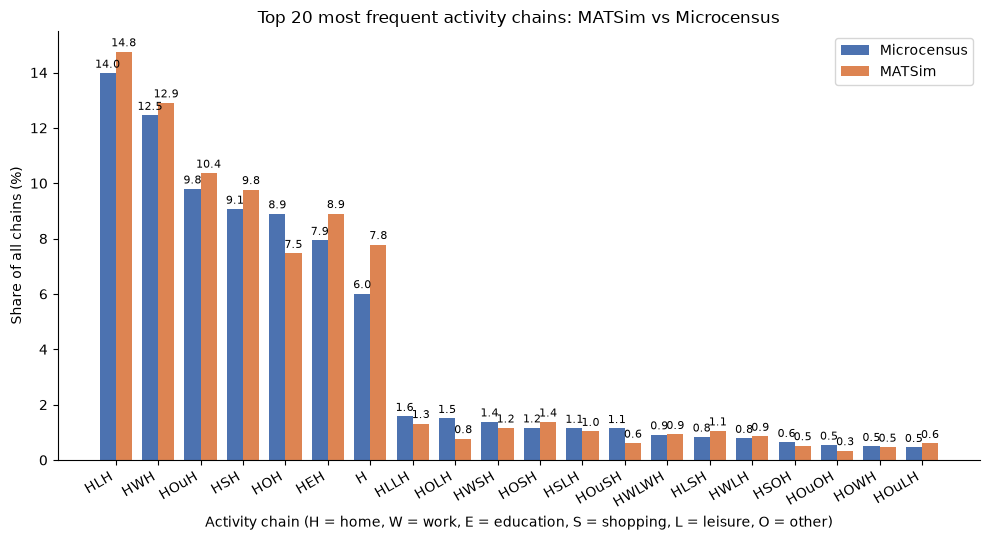

Saved chain_comparison_outside_ignored_top20.png


In [23]:
import matplotlib.pyplot as plt
import numpy as np

def plot_top_chains(res, n=14, out="chain_comparison_outside_ignored_top20.png"):
    top = res.head(n)                      # res is already sorted by mz_count
    x = np.arange(len(top))
    w = 0.38

    fig, ax = plt.subplots(figsize=(10, 5.5))
    b1 = ax.bar(x - w/2, top["mz_share_%"], w, label="Microcensus", color="#4C72B0")
    b2 = ax.bar(x + w/2, top["matsim_share_%"], w, label="MATSim", color="#DD8452")

    ax.bar_label(b1, fmt="%.1f", padding=2, fontsize=8)
    ax.bar_label(b2, fmt="%.1f", padding=2, fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(top.index, rotation=30, ha="right")
    ax.set_xlabel("Activity chain (H = home, W = work, E = education, S = shopping, L = leisure, O = other)")
    ax.set_ylabel("Share of all chains (%)")
    ax.set_title(f"Top {n} most frequent activity chains: MATSim vs Microcensus")
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(out, dpi=200)
    plt.show()
    print("Saved", out)

plot_top_chains(res, n=20)

In [12]:
def diagnose_matsim_h():
    types_seen = Counter()
    patterns = Counter()
    n = 0
    with gzip.open(MATSIM, "rb") as f:
        for _, el in ET.iterparse(f, events=("end",)):
            if el.tag != "person":
                continue
            plans = el.findall("plan")
            plan = next((p for p in plans if p.get("selected") == "yes"), plans[0] if plans else None)
            if plan is not None and plan.find("leg") is not None:
                raw = [a.get("type", "") for a in plan.findall("activity")]
                types_seen.update(raw)
                seq = []
                for t in raw:
                    if t == MATSIM_HOME:
                        seq.append("H")
                    elif t in MATSIM_MAP:
                        seq.append(MATSIM_MAP[t])
                if not tours(seq):
                    n += 1
                    patterns[tuple(raw)] += 1
            el.clear()
    print("persons with legs but no tour:", n)
    print("\nall activity types in file:")
    for t, c in types_seen.most_common():
        print(f"  {t!r:30} {c:8d}  {'mapped' if t in MATSIM_MAP or t == MATSIM_HOME else 'IGNORED'}")
    print("\ntop raw activity sequences among these persons:")
    for p, c in patterns.most_common(15):
        print(c, p)

diagnose_matsim_h()

persons with legs but no tour: 2253

all activity types in file:
  'car interaction'                 87622  IGNORED
  'home'                            77007  mapped
  'pt interaction'                  71504  IGNORED
  'car_passenger interaction'       21242  IGNORED
  'outside'                         18894  mapped
  'leisure'                         17750  mapped
  'work'                            13417  mapped
  'shop'                            11294  mapped
  'other'                           10731  mapped
  'education'                        6724  mapped
  'bike interaction'                 6048  IGNORED
  'work_secondary'                   2573  IGNORED
  'home_secondary'                    698  IGNORED
  'education_secondary'               158  IGNORED

top raw activity sequences among these persons:
449 ('home', 'home')
104 ('home', 'home', 'home')
94 ('outside', 'car interaction', 'car interaction', 'home')
85 ('home', 'car interaction', 'car interaction', 'outside')
80 ('ho

MATSim: 32766 persons, 46877 tours (incl. H), H persons: 3650
{'ok': 27528, 'excluded': 1588, 'home': 3650}
MATSim persons by gender: {'Men': 16034, 'Women': 16732}
survey-day distribution in area households:
tag
1    316
2    304
3    259
4    244
5    232
6    245
7    343
MZ target persons by gender: {'Women': 743, 'Men': 612}
households in area after weekday filter: 1355 (of 1943)


C:\Users\Sylvain\AppData\Local\Temp\ipykernel_13964\2881992981.py:311: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  zp["gender"] = codes.map(MZ_GENDER).fillna("Unknown")


microcensus trip rows kept after household/weekday filter: 5360
boundary CRS: EPSG:2056
trips with missing/invalid destination coords: 0
trips labelled Ou: 585 of 5360
H households: 124 (no trips at all: 83, trips present but no tour: 41) | weighted: 135.2
MZ: 1272 households with trips, weighted tours incl. H: 2248.3

Men:
       matsim_count  mz_count  matsim_share_%  mz_share_%  diff_pp
chain                                                             
HLH          3544.0    149.45           15.39       14.57     0.82
HWH          3440.0    139.72           14.93       13.62     1.31
HOuH         2713.0    126.78           11.78       12.36    -0.58
HEH          2142.0     97.30            9.30        9.49    -0.19
HSH          1871.0     72.89            8.12        7.11     1.02
HOH          1471.0     61.01            6.39        5.95     0.44
H            1438.0     56.76            6.24        5.53     0.71
HLLH          336.0     17.16            1.46        1.67    -0.21
HOLH

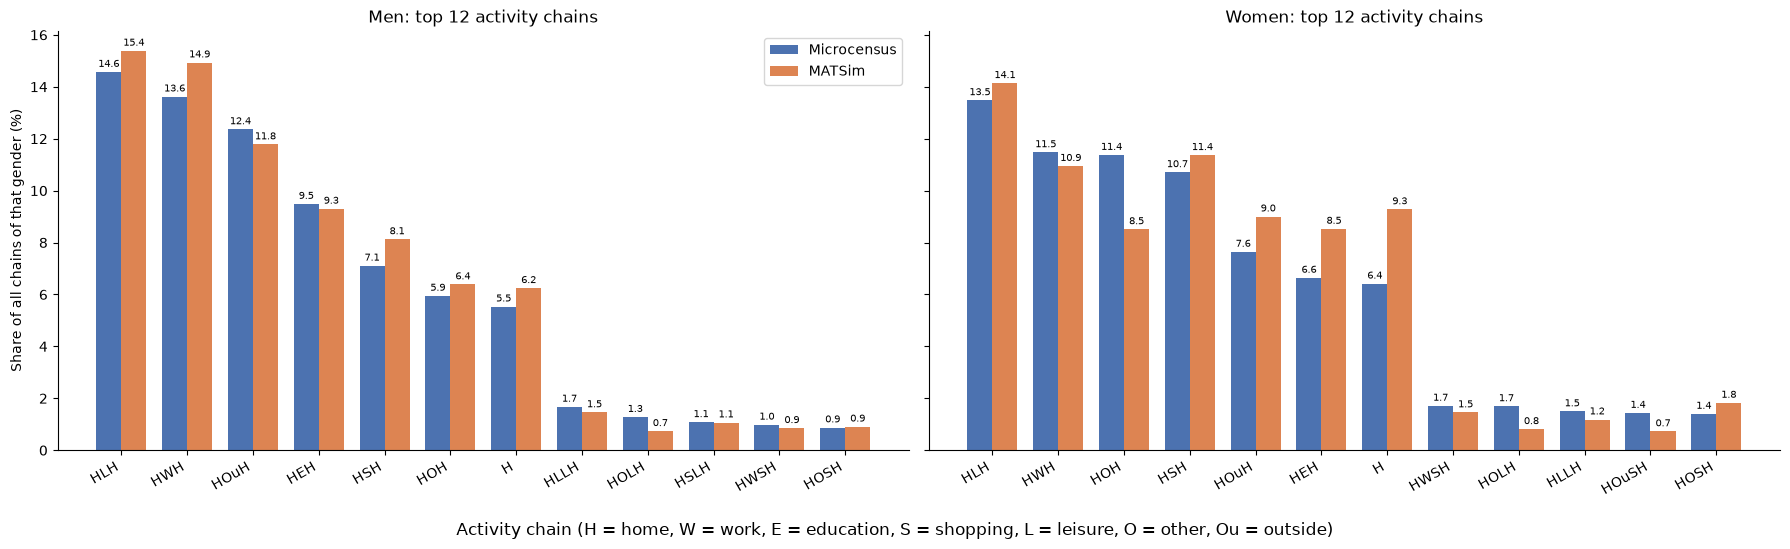

Saved chain_comparison_by_gender.png


In [26]:
"""
Compare activity-chain (tour) shares between a MATSim population and the
Swiss Microcensus (MZ) for the Lausanne study area.

A "chain" is a home-based tour written as a string of one-letter activity codes,
e.g. "HWH" = home -> work -> home, "HWSH" = home -> work -> shop -> home.

    H  home          W  work         E  education
    S  shop          L  leisure      O  other
    Ou activity outside the study area

Persons/households that never leave home are counted as the chain "H".

Chains are counted separately for men and women. Shares are computed within
each gender, so "x% of women's tours are HWH" is compared between the sources.

Output: chain_comparison_men.csv / chain_comparison_women.csv (counts, shares and
difference in percentage points) and a two-panel plot (men | women).
"""

import gzip
import re
import xml.etree.ElementTree as ET
from collections import Counter

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely

# =============================================================================
# CONFIGURATION
# =============================================================================

# ---- input / output paths ---------------------------------------------------
MATSIM_PLANS = r"working_rep\filterred_data\lausanne_population_filtered_age6plus.xml.gz"
MZ_TRIPS = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\wege.csv"
MZ_PERSONS = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\zielpersonen.csv"
MZ_HOUSEHOLDS_IN_AREA = r"working_rep\filterred_data\mz\household_ids_in_area.csv"
BOUNDARY_SHP = (r"C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\Lausanne_10pct"
                r"\Lausanne_10pct\Boundary\LausanneExtent.shp")
OUTPUT_PREFIX = "chain_comparison"   # -> chain_comparison_men.csv, ..._women.csv, ..._by_gender.png
MZ_HOUSEHOLD_PERSONS = (r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus"
                        r"\haushaltspersonen.csv")   # only used if gender is not in zielpersonen

# ---- microcensus column names (all lower case, see read_csv_clean) ----------
HH_COL = "hhnr"          # household id (used as the "person" key throughout)
ORDER_COL = "f51100"     # trip order within the day (negative = invalid)
PURPOSE_COL = "wzweck1"  # trip purpose code of the trip's destination
WEIGHT_COL = "wp"        # person weight
OUTING_COL = "ausnr"     # outing id (a home-to-home excursion)
DEST_X_COL = "z_x"       # destination longitude (WGS84)
DEST_Y_COL = "z_y"       # destination latitude  (WGS84)

# ---- survey-day filter (columns of zielpersonen.csv) ------------------------
DAY_COL = "tag"                # 1 = Monday ... 7 = Sunday
KEEP_DAYS = {1, 2, 3, 4, 5}    # weekdays only

# ---- optional age filter on the MZ side -------------------------------------
AGE_COL = None   # e.g. "alter"; None disables the filter
MIN_AGE = 6

# ---- gender -------------------------------------------------------------------
GENDER_COL = "gesl"                      # MZ gender column: 1 = man, 2 = woman
MZ_GENDER = {1: "Men", 2: "Women"}
MATSIM_GENDER = {"m": "Men", "f": "Women"}   # <attribute name="sex"> in the plans file
GENDERS = ("Men", "Women")
# Only needed if `gesl` is NOT in zielpersonen.csv: a person-number column that
# exists in both zielpersonen.csv and haushaltspersonen.csv (e.g. "zielpnr").
PERSON_ID_COL = None

# ---- MZ purpose code -> chain letter ----------------------------------------
MZ_HOME = 11
MZ_MAP = {
    1: "O", 2: "W", 3: "E", 4: "S", 5: "O", 6: "W",
    7: "O", 8: "L", 9: "O", 10: "O", 12: "O", 13: "O",
}

# ---- MATSim activity type -> chain letter -----------------------------------
MATSIM_HOME = "home"
MATSIM_MAP = {
    "work": "W", "education": "E", "shop": "S", "leisure": "L",
    "other": "O", "outside": "Ou",
    "work_secondary": "W", "education_secondary": "E",
    "home_secondary": "O",   # judgment call: secondary homes count as "other"
}

# ---- how tours are built ----------------------------------------------------
# MZ: build one tour per outing (True) or per household-day (False)
USE_OUTINGS = True
# MZ (only if USE_OUTINGS is False): merge consecutive trips with the same purpose
COLLAPSE_RETURN_PAIRS = True
# MATSim: how to treat plans that do not start and end at home
#   "drop"   - keep only the complete H...H tours inside the plan
#   "cyclic" - rotate the plan so it starts at the first home, then close it
#   "insert" - add a home at the start and/or end
CLOSE_MODE = "drop"


# =============================================================================
# CHAIN HELPERS (shared by MATSim and MZ)
# =============================================================================

def merge_outside(chain: str) -> str:
    """Collapse consecutive 'Ou' stops into one: HOuOuOuH -> HOuH."""
    return re.sub(r"(?:Ou)+", "Ou", chain)


def split_into_tours(codes: list[str]) -> list[str]:
    """
    Cut a sequence of letters at every 'H' and return the complete
    home-to-home tours. Anything before the first H or after the last H
    is discarded (it is not a closed tour).

    ["H", "W", "H", "S", "L", "H"] -> ["HWH", "HSLH"]
    """
    tours, current, started = [], [], False
    for code in codes:
        if code == "H":
            if started and current:          # a tour just closed
                tours.append("H" + "".join(current) + "H")
            current, started = [], True      # this H also opens the next tour
        elif started:
            current.append(code)
    return tours


def plan_tours(seq: list[str], mode: str) -> tuple[list[str], str]:
    """
    Turn one daily activity sequence into tours.

    Returns (tours, status) where status is
        'home'     - only home activities (or nothing): person stays home
        'excluded' - no usable tour could be built (no home anchor at all)
        'ok'       - plan was already complete (or yielded tours in 'drop' mode)
        'closed'   - plan was repaired according to `mode`
    """
    if all(c == "H" for c in seq):
        return [], "home"
    if "H" not in seq:
        return [], "excluded"

    # Plan already starts and ends at home: nothing to repair
    if seq[0] == "H" and seq[-1] == "H":
        return split_into_tours(seq), "ok"

    if mode == "drop":
        tours = split_into_tours(seq)
        return tours, ("ok" if tours else "excluded")

    if mode == "cyclic":
        first_home = seq.index("H")
        seq = seq[first_home:] + seq[:first_home] + ["H"]
    else:  # "insert"
        if seq[0] != "H":
            seq = ["H"] + seq
        if seq[-1] != "H":
            seq = seq + ["H"]
    return split_into_tours(seq), "closed"


# =============================================================================
# MATSIM
# =============================================================================

def person_gender(person_el) -> str:
    """Gender from the person's <attribute name="sex"> ('Unknown' if absent)."""
    attrs = person_el.find("attributes")
    if attrs is not None:
        for a in attrs.findall("attribute"):
            if a.get("name") == "sex":
                return MATSIM_GENDER.get((a.text or "").strip().lower(), "Unknown")
    return "Unknown"


def matsim_chains() -> Counter:
    """Count tours (and stay-at-home persons as 'H') per (gender, chain)."""
    status_counts = Counter()   # how each person's plan was handled
    gender_counts = Counter()   # persons per gender
    chains = Counter()          # (gender, chain string) -> number of occurrences
    n_persons = 0

    with gzip.open(MATSIM_PLANS, "rb") as f:
        # Stream the XML so the whole population never sits in memory
        for _, el in ET.iterparse(f, events=("end",)):
            if el.tag != "person":
                continue
            n_persons += 1
            gender = person_gender(el)
            gender_counts[gender] += 1

            # Use the selected plan, falling back to the first one
            plans = el.findall("plan")
            plan = next((p for p in plans if p.get("selected") == "yes"),
                        plans[0] if plans else None)

            tours, status = [], "home"
            if plan is not None and plan.find("leg") is not None:
                # Translate activity types to letters; unknown types are skipped
                seq = []
                for act in plan.findall("activity"):
                    act_type = act.get("type", "")
                    if act_type == MATSIM_HOME:
                        seq.append("H")
                    elif act_type in MATSIM_MAP:
                        seq.append(MATSIM_MAP[act_type])
                tours, status = plan_tours(seq, CLOSE_MODE)
                tours = [merge_outside(t) for t in tours]

            status_counts[status] += 1
            if tours:
                chains.update((gender, t) for t in tours)
            elif status == "home":
                chains[(gender, "H")] += 1
            # 'excluded' persons are not counted anywhere

            el.clear()  # free memory

    n_home = sum(v for (_, c), v in chains.items() if c == "H")
    print(f"MATSim: {n_persons} persons, {sum(chains.values())} tours (incl. H), "
          f"H persons: {n_home}")
    print(dict(status_counts))
    print("MATSim persons by gender:", dict(gender_counts))
    return chains


# =============================================================================
# MICROCENSUS
# =============================================================================

def read_csv_clean(path: str) -> pd.DataFrame:
    """
    Read a CSV whose encoding and separator are unknown.
    Tries several encodings; for each, picks the separator that yields the most
    columns. Column names are stripped and lower-cased.
    """
    for encoding in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            candidates = [pd.read_csv(path, sep=sep, encoding=encoding, low_memory=False)
                          for sep in (",", ";", "\t")]
        except UnicodeDecodeError:
            continue  # wrong encoding, try the next one
        df = max(candidates, key=lambda d: d.shape[1])
        df.columns = [str(c).strip().lower() for c in df.columns]
        return df
    raise ValueError(f"Could not decode {path} with any known encoding")


def require_columns(df: pd.DataFrame, cols: list[str], name: str) -> None:
    """Exit with a helpful message if expected columns are missing."""
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise SystemExit(f"Missing columns {missing} in {name}. "
                         f"Available: {list(df.columns)}")


def inside_area_mask(df: pd.DataFrame, x_col: str, y_col: str) -> pd.Series:
    """True for rows whose (x, y) point lies inside the study-area boundary."""
    area = gpd.read_file(BOUNDARY_SHP)
    print("boundary CRS:", area.crs)
    area = area.to_crs(epsg=4326)  # MZ coordinates are WGS84
    # union_all() replaces the deprecated unary_union in newer geopandas
    polygon = (area.geometry.union_all() if hasattr(area.geometry, "union_all")
               else area.unary_union)

    x = pd.to_numeric(df[x_col], errors="coerce")
    y = pd.to_numeric(df[y_col], errors="coerce")
    valid = x.notna() & y.notna()

    mask = pd.Series(False, index=df.index)
    mask[valid] = shapely.contains_xy(polygon, x[valid].to_numpy(), y[valid].to_numpy())
    print(f"trips with missing/invalid destination coords: {(~valid).sum()}")
    return mask


def load_area_households() -> set:
    """Household ids that lie in the study area."""
    hh = read_csv_clean(MZ_HOUSEHOLDS_IN_AREA)
    if HH_COL in hh.columns:
        ids = hh[HH_COL]
    elif hh.shape[1] == 1:          # headerless single-column file
        ids = hh.iloc[:, 0]
    else:
        raise SystemExit(f"No '{HH_COL}' column in household file. "
                         f"Columns: {list(hh.columns)}")
    return set(pd.to_numeric(ids, errors="coerce").dropna())


def attach_gender(zp: pd.DataFrame) -> pd.DataFrame:
    """
    Add a 'gender' column ('Men' / 'Women' / 'Unknown') to the target persons.
    Uses `gesl` from zielpersonen.csv if present; otherwise looks it up in
    haushaltspersonen.csv via HH_COL + PERSON_ID_COL.
    """
    if GENDER_COL not in zp.columns:
        if PERSON_ID_COL is None:
            raise SystemExit(f"'{GENDER_COL}' is not in zielpersonen. Set PERSON_ID_COL to a "
                             f"person-number column shared with haushaltspersonen.csv.")
        hp = read_csv_clean(MZ_HOUSEHOLD_PERSONS)
        require_columns(hp, [HH_COL, PERSON_ID_COL, GENDER_COL], "haushaltspersonen")
        require_columns(zp, [PERSON_ID_COL], "zielpersonen")
        keys = [HH_COL, PERSON_ID_COL]
        hp = hp[keys + [GENDER_COL]].copy()
        for col in keys:
            hp[col] = pd.to_numeric(hp[col], errors="coerce")
            zp[col] = pd.to_numeric(zp[col], errors="coerce")
        zp = zp.merge(hp.drop_duplicates(keys), on=keys, how="left")

    codes = pd.to_numeric(zp[GENDER_COL], errors="coerce")
    zp["gender"] = codes.map(MZ_GENDER).fillna("Unknown")
    print("MZ target persons by gender:", zp["gender"].value_counts().to_dict())
    return zp


def load_target_persons(area_hh_ids: set) -> pd.DataFrame:
    """
    Target persons living in the area, restricted to surveyed weekdays
    (and optionally to a minimum age). One row per household.
    """
    zp = read_csv_clean(MZ_PERSONS)
    require_columns(zp, [HH_COL, DAY_COL, WEIGHT_COL], "zielpersonen")
    for col in (HH_COL, DAY_COL, WEIGHT_COL):
        zp[col] = pd.to_numeric(zp[col], errors="coerce")

    in_area = zp[HH_COL].isin(area_hh_ids)
    print("survey-day distribution in area households:")
    print(zp[in_area][DAY_COL].value_counts().sort_index().to_string())

    zp = zp[in_area & zp[DAY_COL].isin(KEEP_DAYS)]
    if AGE_COL:
        age = pd.to_numeric(zp[AGE_COL.lower()], errors="coerce")
        zp = zp[age >= MIN_AGE]
    return attach_gender(zp.drop_duplicates(HH_COL))


def load_trips(hh_ids: set) -> pd.DataFrame:
    """
    Valid trips of the given households, sorted by household and trip order,
    with an extra boolean column `_outside` (destination outside the area).
    """
    df = read_csv_clean(MZ_TRIPS)
    require_columns(df, [HH_COL, ORDER_COL, PURPOSE_COL,
                         DEST_X_COL, DEST_Y_COL, WEIGHT_COL], "wege")
    df[HH_COL] = pd.to_numeric(df[HH_COL], errors="coerce")
    df[WEIGHT_COL] = pd.to_numeric(df[WEIGHT_COL], errors="coerce")
    df = df[df[HH_COL].isin(hh_ids)]
    print("microcensus trip rows kept after household/weekday filter:", len(df))

    # Negative trip order = invalid/missing trip
    df = df[pd.to_numeric(df[ORDER_COL], errors="coerce") >= 0].copy()
    df[PURPOSE_COL] = pd.to_numeric(df[PURPOSE_COL], errors="coerce")

    # Destination outside the boundary (trips without coordinates are NOT outside)
    inside = inside_area_mask(df, DEST_X_COL, DEST_Y_COL)
    has_coords = (pd.to_numeric(df[DEST_X_COL], errors="coerce").notna()
                  & pd.to_numeric(df[DEST_Y_COL], errors="coerce").notna())
    df["_outside"] = has_coords & ~inside
    print(f"trips labelled Ou: {int(df['_outside'].sum())} of {len(df)}")

    return df.sort_values([HH_COL, ORDER_COL])


def to_letters(purposes, outside_flags) -> list[str]:
    """
    Map MZ purpose codes to chain letters. Home trips and unknown codes are
    dropped; trips whose destination is outside the area become 'Ou'.
    """
    letters = []
    for code, outside in zip(purposes, outside_flags):
        if code == MZ_HOME:
            continue
        letter = "Ou" if outside else MZ_MAP.get(code)
        if letter:
            letters.append(letter)
    return letters


def household_tours(trips: pd.DataFrame) -> list[str]:
    """Build the tour strings for one household from its ordered trips."""
    purposes, outside = trips[PURPOSE_COL], trips["_outside"]

    # --- Option 1: one tour per outing ---------------------------------------
    if USE_OUTINGS and OUTING_COL in trips.columns:
        tours = []
        for _, outing in trips.groupby(OUTING_COL, sort=False):
            # The last trip of an outing leads back home, so drop it
            acts = to_letters(outing[PURPOSE_COL].iloc[:-1],
                              outing["_outside"].iloc[:-1])
            if acts:
                tours.append(merge_outside("H" + "".join(acts) + "H"))
        return tours

    pairs = list(zip(purposes, outside))

    # --- Option 2: a single tour per day, consecutive duplicates merged ------
    if COLLAPSE_RETURN_PAIRS:
        kept = [p for i, p in enumerate(pairs) if i == 0 or p[0] != pairs[i - 1][0]]
        acts = to_letters(*zip(*kept)) if kept else []
        return [merge_outside("H" + "".join(acts) + "H")] if acts else []

    # --- Option 3: split the day at every explicit home trip -----------------
    seq = ["H"]
    for code, out in pairs:
        if code == MZ_HOME:
            seq.append("H")
        else:
            seq.extend(to_letters([code], [out]))
    return [merge_outside(t) for t in split_into_tours(seq)]


def mz_chains() -> Counter:
    """
    Weighted tour counts from the microcensus. Weekday households in the area
    that produce no tour are added as weighted 'H' (stay-at-home) entries.
    """
    area_hh_ids = load_area_households()
    persons = load_target_persons(area_hh_ids)
    weekday_hh = set(persons[HH_COL].dropna())
    print(f"households in area after weekday filter: {len(weekday_hh)} "
          f"(of {len(area_hh_ids)})")

    trips = load_trips(weekday_hh)
    gender_of = persons.set_index(HH_COL)["gender"].to_dict()   # household -> gender

    chains = Counter()
    producing_hh = set()   # households that yielded at least one tour
    n_hh_with_trips = 0

    for hh_id, group in trips.groupby(HH_COL):
        n_hh_with_trips += 1
        weight = group[WEIGHT_COL].iloc[0]
        if pd.isna(weight):
            continue
        for tour in household_tours(group):
            chains[(gender_of[hh_id], tour)] += weight
            producing_hh.add(hh_id)

    # --- stay-at-home: weekday households without any tour -------------------
    no_tour_hh = weekday_hh - producing_hh
    home_by_gender = (persons[persons[HH_COL].isin(no_tour_hh)]
                      .groupby("gender")[WEIGHT_COL].sum())
    for gender, w in home_by_gender.items():
        chains[(gender, "H")] += w
    home_weight = home_by_gender.sum()

    n_no_trips = len(weekday_hh - set(trips[HH_COL].dropna()))
    print(f"H households: {len(no_tour_hh)} (no trips at all: {n_no_trips}, "
          f"trips present but no tour: {len(no_tour_hh) - n_no_trips}) "
          f"| weighted: {home_weight:.1f}")
    print(f"MZ: {n_hh_with_trips} households with trips, "
          f"weighted tours incl. H: {sum(chains.values()):.1f}")
    return chains


# =============================================================================
# MAIN
# =============================================================================

def compare(matsim: Counter, mz: Counter, gender: str) -> pd.DataFrame:
    """Side-by-side chain table for one gender, with shares computed within it."""
    m = {chain: v for (g, chain), v in matsim.items() if g == gender}
    z = {chain: v for (g, chain), v in mz.items() if g == gender}

    # One row per chain, one column per source; missing chains count as 0
    res = pd.DataFrame({"matsim_count": pd.Series(m),
                        "mz_count": pd.Series(z)}).fillna(0)

    # Shares in % and the gap between the two sources (percentage points)
    res["matsim_share_%"] = 100 * res["matsim_count"] / res["matsim_count"].sum()
    res["mz_share_%"] = 100 * res["mz_count"] / res["mz_count"].sum()
    res["diff_pp"] = res["matsim_share_%"] - res["mz_share_%"]

    res.index.name = "chain"
    return res.sort_values("mz_count", ascending=False)


def plot_top_chains_by_gender(res_by_gender: dict, n: int = 12,
                              out: str = f"{OUTPUT_PREFIX}_by_gender.png") -> None:
    """One panel per gender: MZ vs MATSim share of the `n` most frequent chains."""
    w = 0.38
    fig, axes = plt.subplots(1, len(res_by_gender), figsize=(18, 5.5), sharey=True)

    for ax, (label, res) in zip(axes, res_by_gender.items()):
        top = res.head(n)   # res is already sorted by mz_count
        x = np.arange(len(top))

        b1 = ax.bar(x - w / 2, top["mz_share_%"], w, label="Microcensus", color="#4C72B0")
        b2 = ax.bar(x + w / 2, top["matsim_share_%"], w, label="MATSim", color="#DD8452")
        ax.bar_label(b1, fmt="%.1f", padding=2, fontsize=7)
        ax.bar_label(b2, fmt="%.1f", padding=2, fontsize=7)

        ax.set_xticks(x)
        ax.set_xticklabels(top.index, rotation=30, ha="right")
        ax.set_title(f"{label}: top {n} activity chains")
        ax.spines[["top", "right"]].set_visible(False)

    axes[0].set_ylabel("Share of all chains of that gender (%)")
    axes[0].legend()
    fig.supxlabel("Activity chain (H = home, W = work, E = education, "
                  "S = shopping, L = leisure, O = other, Ou = outside)")
    fig.tight_layout()
    fig.savefig(out, dpi=200)
    plt.show()
    print("Saved", out)


def main() -> None:
    matsim, mz = matsim_chains(), mz_chains()

    res_by_gender = {}
    for gender in GENDERS:
        res = compare(matsim, mz, gender)
        res_by_gender[gender] = res
        csv_path = f"{OUTPUT_PREFIX}_{gender.lower()}.csv"
        res.round(2).to_csv(csv_path)
        print(f"\n{gender}:")
        print(res.head(20).round(2))
        print("Saved", csv_path)

    plot_top_chains_by_gender(res_by_gender, n=12)


if __name__ == "__main__":
    main()

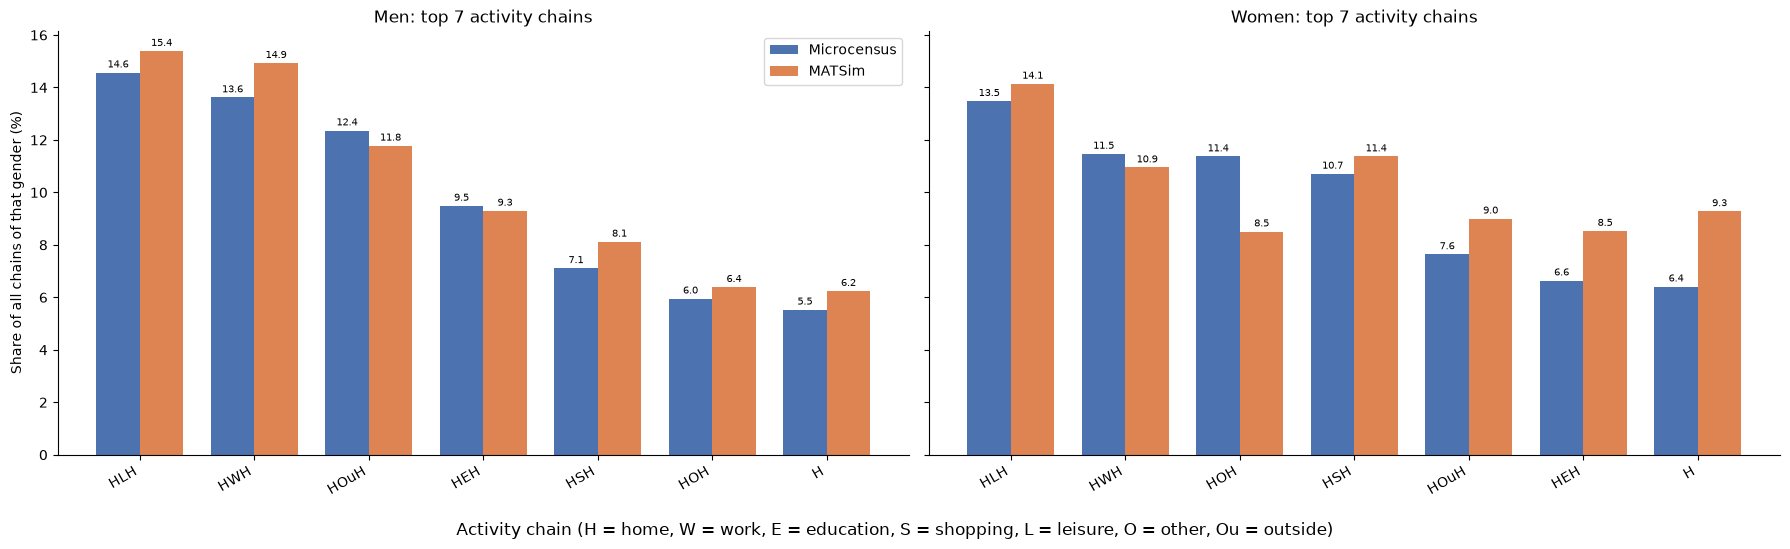

Saved chain_comparison_by_gender.png


In [30]:
import matplotlib.pyplot as plt
import numpy as np

res_men = pd.read_csv("chain_comparison_men.csv", index_col="chain")
res_women = pd.read_csv("chain_comparison_women.csv", index_col="chain")

def plot_top_chains_by_gender(res_by_gender, n=14, out="chain_comparison_by_gender.png"):
    """
    res_by_gender: dict like {"Men": res_men, "Women": res_women}.
    Each value is a DataFrame with the same columns as before
    (mz_share_%, matsim_share_%), shares computed within that gender.
    """
    w = 0.38
    fig, axes = plt.subplots(1, len(res_by_gender), figsize=(18, 5.5), sharey=True)

    for ax, (label, res) in zip(axes, res_by_gender.items()):
        top = res.sort_values("mz_count", ascending=False).head(n)
        x = np.arange(len(top))

        b1 = ax.bar(x - w/2, top["mz_share_%"], w, label="Microcensus", color="#4C72B0")
        b2 = ax.bar(x + w/2, top["matsim_share_%"], w, label="MATSim", color="#DD8452")
        ax.bar_label(b1, fmt="%.1f", padding=2, fontsize=7)
        ax.bar_label(b2, fmt="%.1f", padding=2, fontsize=7)

        ax.set_xticks(x)
        ax.set_xticklabels(top.index, rotation=30, ha="right")
        ax.set_title(f"{label}: top {n} activity chains")
        ax.spines[["top", "right"]].set_visible(False)

    axes[0].set_ylabel("Share of all chains of that gender (%)")
    axes[0].legend()
    fig.supxlabel("Activity chain (H = home, W = work, E = education, "
                  "S = shopping, L = leisure, O = other, Ou = outside)")
    fig.tight_layout()
    fig.savefig(out, dpi=200)
    plt.show()
    print("Saved", out)

plot_top_chains_by_gender({"Men": res_men, "Women": res_women}, n=7)

MATSim: 32766 persons, 46877 tours (incl. H), H persons: 3650
{'ok': 27528, 'excluded': 1588, 'home': 3650}
MATSim persons by gender: {'Men': 16034, 'Women': 16732}
survey-day distribution in area households:
tag
1    316
2    304
3    259
4    244
5    232
6    245
7    343
MZ target persons by gender: {'Women': 743, 'Men': 612}
households in area after weekday filter: 1355 (of 1943)


C:\Users\Sylvain\AppData\Local\Temp\ipykernel_16360\1044917940.py:324: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  zp["gender"] = codes.map(MZ_GENDER).fillna("Unknown")


microcensus trip rows kept after household/weekday filter: 5360
boundary CRS: EPSG:2056
trips with missing/invalid destination coords: 0
trips labelled Ou: 585 of 5360
H households: 124 (no trips at all: 83, trips present but no tour: 41) | weighted: 135.2
MZ: 1272 households with trips, weighted tours incl. H: 2248.3

Men:
       matsim_count  mz_count  matsim_share_%  mz_share_%  diff_pp
chain                                                             
HLH          3544.0    149.45           15.39       14.57     0.82
HWH          3440.0    139.72           14.93       13.62     1.31
HOuH         2713.0    126.78           11.78       12.36    -0.58
HEH          2142.0     97.30            9.30        9.49    -0.19
HSH          1871.0     72.89            8.12        7.11     1.02
HOH          1471.0     61.01            6.39        5.95     0.44
H            1438.0     56.76            6.24        5.53     0.71
HLLH          336.0     17.16            1.46        1.67    -0.21
HOLH

C:\Users\Sylvain\AppData\Local\Temp\ipykernel_16360\1044917940.py:324: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  zp["gender"] = codes.map(MZ_GENDER).fillna("Unknown")


microcensus trip rows kept after household/weekday filter: 5360
boundary CRS: EPSG:2056
trips with missing/invalid destination coords: 0
trips labelled Ou: 585 of 5360


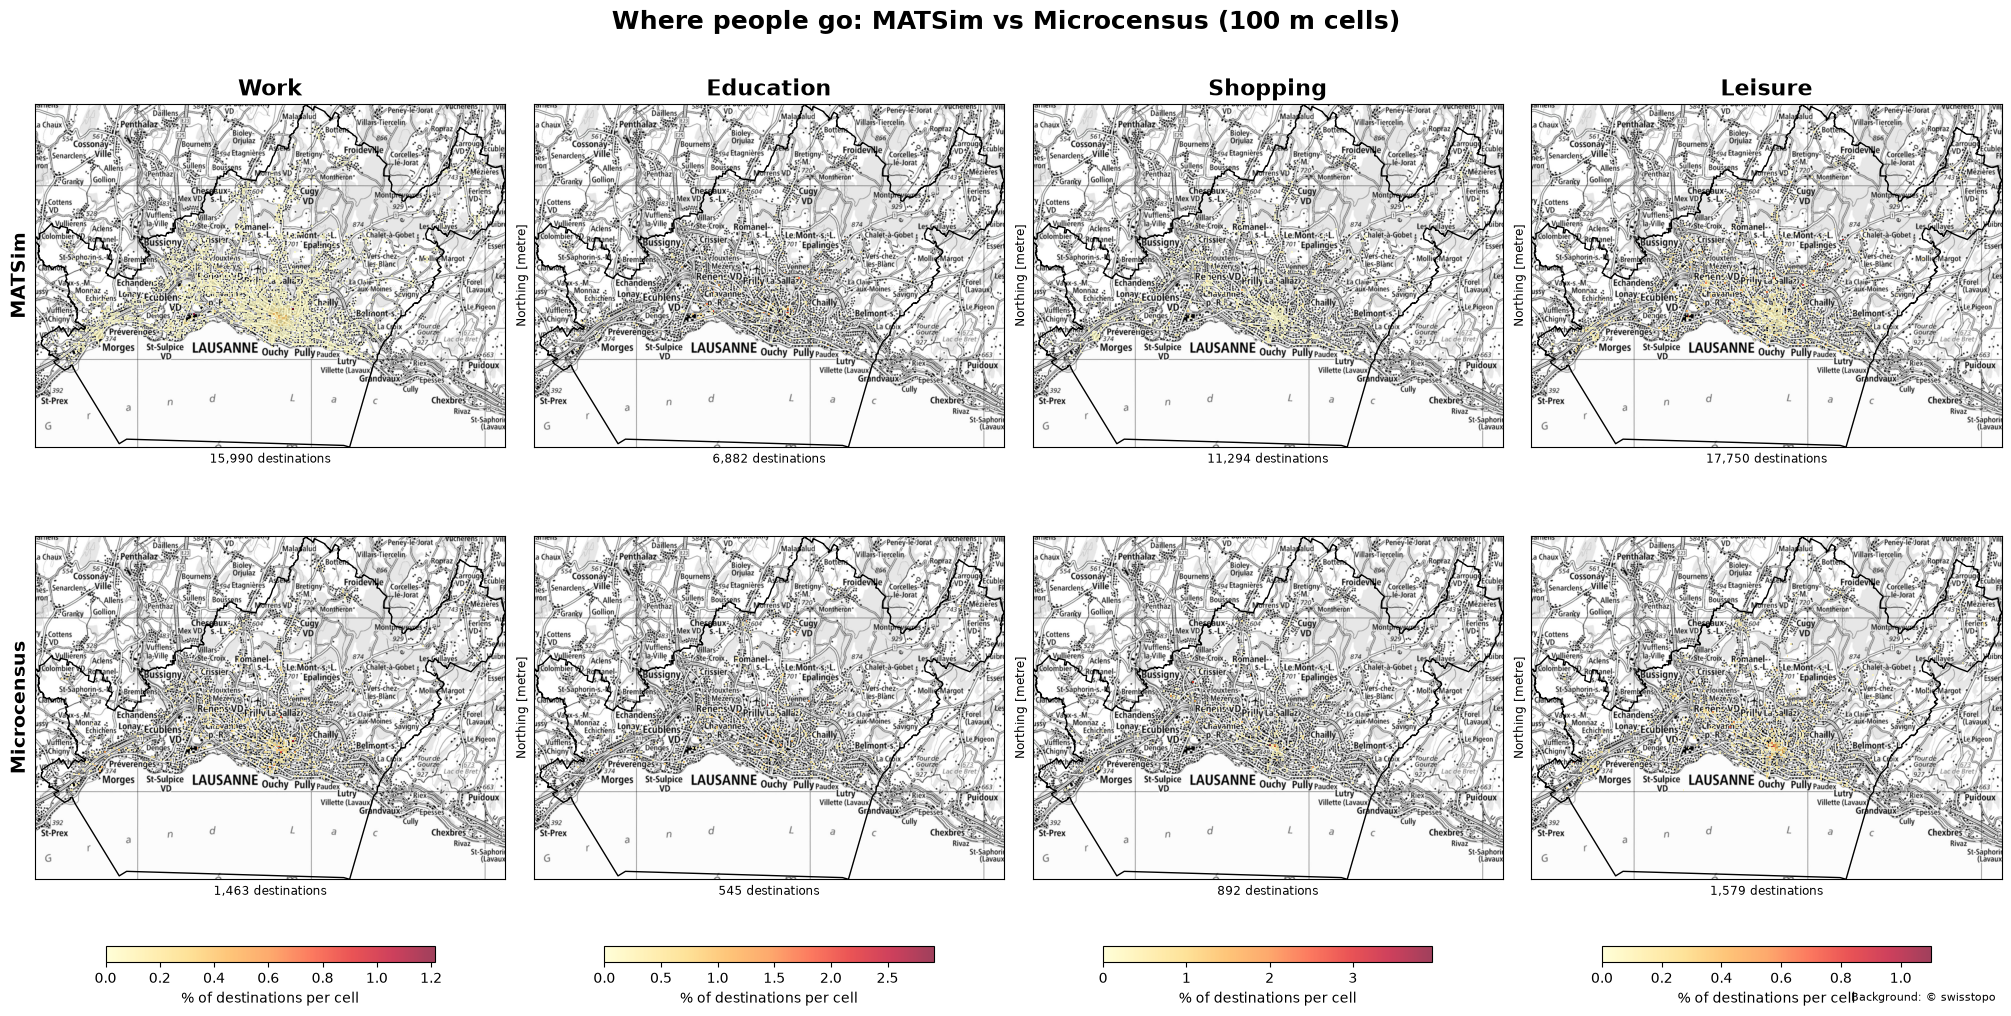

Saved chain_comparison_destination_maps.png


In [ ]:
"""
Compare activity-chain (tour) shares between a MATSim population and the
Swiss Microcensus (MZ) for the Lausanne study area.

A "chain" is a home-based tour written as a string of one-letter activity codes,
e.g. "HWH" = home -> work -> home, "HWSH" = home -> work -> shop -> home.

    H  home          W  work         E  education
    S  shop          L  leisure      O  other
    Ou activity outside the study area

Persons/households that never leave home are counted as the chain "H".

Chains are counted separately for men and women. Shares are computed within
each gender, so "x% of women's tours are HWH" is compared between the sources.

Output: chain_comparison_men.csv / chain_comparison_women.csv (counts, shares and
difference in percentage points) and a
2 x 4 grid of destination maps (MATSim | Microcensus x work, education,
shopping, leisure) on a swisstopo background.
"""

import gzip
import re
import xml.etree.ElementTree as ET
from collections import Counter

import contextily as ctx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely

# =============================================================================
# CONFIGURATION
# =============================================================================

# ---- input / output paths ---------------------------------------------------
MATSIM_PLANS = r"working_rep\filterred_data\lausanne_population_filtered_age6plus.xml.gz"
MZ_TRIPS = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\wege.csv"
MZ_PERSONS = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\zielpersonen.csv"
MZ_HOUSEHOLDS_IN_AREA = r"working_rep\filterred_data\mz\household_ids_in_area.csv"
BOUNDARY_SHP = (r"C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\Lausanne_10pct"
                r"\Lausanne_10pct\Boundary\LausanneExtent.shp")
OUTPUT_PREFIX = "chain_comparison"   # -> chain_comparison_men.csv, ..._women.csv, ..._by_gender.png
MZ_HOUSEHOLD_PERSONS = (r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus"
                        r"\haushaltspersonen.csv")   # only used if gender is not in zielpersonen

# ---- microcensus column names (all lower case, see read_csv_clean) ----------
HH_COL = "hhnr"          # household id (used as the "person" key throughout)
ORDER_COL = "f51100"     # trip order within the day (negative = invalid)
PURPOSE_COL = "wzweck1"  # trip purpose code of the trip's destination
WEIGHT_COL = "wp"        # person weight
OUTING_COL = "ausnr"     # outing id (a home-to-home excursion)
DEST_X_COL = "z_x"       # destination longitude (WGS84)
DEST_Y_COL = "z_y"       # destination latitude  (WGS84)

# ---- survey-day filter (columns of zielpersonen.csv) ------------------------
DAY_COL = "tag"                # 1 = Monday ... 7 = Sunday
KEEP_DAYS = {1, 2, 3, 4, 5}    # weekdays only

# ---- optional age filter on the MZ side -------------------------------------
AGE_COL = None   # e.g. "alter"; None disables the filter
MIN_AGE = 6

# ---- gender -------------------------------------------------------------------
GENDER_COL = "gesl"                      # MZ gender column: 1 = man, 2 = woman
MZ_GENDER = {1: "Men", 2: "Women"}
MATSIM_GENDER = {"m": "Men", "f": "Women"}   # <attribute name="sex"> in the plans file
GENDERS = ("Men", "Women")
# Only needed if `gesl` is NOT in zielpersonen.csv: a person-number column that
# exists in both zielpersonen.csv and haushaltspersonen.csv (e.g. "zielpnr").
PERSON_ID_COL = None

# ---- destination maps -----------------------------------------------------------
MATSIM_CRS = 2056        # MATSim coordinates are Swiss LV95 (EPSG:2056)
MAP_CELL_M = 500         # grid cell size of the maps, in metres
# swisstopo grey national map (Web-Mercator tiles); needs internet access.
# Use "ch.swisstopo.pixelkarte-farbe" instead of "-grau" for the coloured map.
SWISSTOPO_TILES = ("https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.pixelkarte-grau/"
                   "default/current/3857/{z}/{x}/{y}.jpeg")
MAP_ZOOM = 13            # tile zoom level (higher = sharper but more tiles)
MAP_PURPOSES = {"W": "Work", "E": "Education", "S": "Shopping", "L": "Leisure"}

# ---- MZ purpose code -> chain letter ----------------------------------------
MZ_HOME = 11
MZ_MAP = {
    1: "O", 2: "W", 3: "E", 4: "S", 5: "O", 6: "W",
    7: "O", 8: "L", 9: "O", 10: "O", 12: "O", 13: "O",
}

# ---- MATSim activity type -> chain letter -----------------------------------
MATSIM_HOME = "home"
MATSIM_MAP = {
    "work": "W", "education": "E", "shop": "S", "leisure": "L",
    "other": "O", "outside": "Ou",
    "work_secondary": "W", "education_secondary": "E",
    "home_secondary": "O",   # judgment call: secondary homes count as "other"
}

# ---- how tours are built ----------------------------------------------------
# MZ: build one tour per outing (True) or per household-day (False)
USE_OUTINGS = True
# MZ (only if USE_OUTINGS is False): merge consecutive trips with the same purpose
COLLAPSE_RETURN_PAIRS = True
# MATSim: how to treat plans that do not start and end at home
#   "drop"   - keep only the complete H...H tours inside the plan
#   "cyclic" - rotate the plan so it starts at the first home, then close it
#   "insert" - add a home at the start and/or end
CLOSE_MODE = "drop"


# =============================================================================
# CHAIN HELPERS (shared by MATSim and MZ)
# =============================================================================

def merge_outside(chain: str) -> str:
    """Collapse consecutive 'Ou' stops into one: HOuOuOuH -> HOuH."""
    return re.sub(r"(?:Ou)+", "Ou", chain)


def split_into_tours(codes: list[str]) -> list[str]:
    """
    Cut a sequence of letters at every 'H' and return the complete
    home-to-home tours. Anything before the first H or after the last H
    is discarded (it is not a closed tour).

    ["H", "W", "H", "S", "L", "H"] -> ["HWH", "HSLH"]
    """
    tours, current, started = [], [], False
    for code in codes:
        if code == "H":
            if started and current:          # a tour just closed
                tours.append("H" + "".join(current) + "H")
            current, started = [], True      # this H also opens the next tour
        elif started:
            current.append(code)
    return tours


def plan_tours(seq: list[str], mode: str) -> tuple[list[str], str]:
    """
    Turn one daily activity sequence into tours.

    Returns (tours, status) where status is
        'home'     - only home activities (or nothing): person stays home
        'excluded' - no usable tour could be built (no home anchor at all)
        'ok'       - plan was already complete (or yielded tours in 'drop' mode)
        'closed'   - plan was repaired according to `mode`
    """
    if all(c == "H" for c in seq):
        return [], "home"
    if "H" not in seq:
        return [], "excluded"

    # Plan already starts and ends at home: nothing to repair
    if seq[0] == "H" and seq[-1] == "H":
        return split_into_tours(seq), "ok"

    if mode == "drop":
        tours = split_into_tours(seq)
        return tours, ("ok" if tours else "excluded")

    if mode == "cyclic":
        first_home = seq.index("H")
        seq = seq[first_home:] + seq[:first_home] + ["H"]
    else:  # "insert"
        if seq[0] != "H":
            seq = ["H"] + seq
        if seq[-1] != "H":
            seq = seq + ["H"]
    return split_into_tours(seq), "closed"


# =============================================================================
# MATSIM
# =============================================================================

def person_gender(person_el) -> str:
    """Gender from the person's <attribute name="sex"> ('Unknown' if absent)."""
    attrs = person_el.find("attributes")
    if attrs is not None:
        for a in attrs.findall("attribute"):
            if a.get("name") == "sex":
                return MATSIM_GENDER.get((a.text or "").strip().lower(), "Unknown")
    return "Unknown"


def matsim_chains() -> Counter:
    """Count tours (and stay-at-home persons as 'H') per (gender, chain)."""
    status_counts = Counter()   # how each person's plan was handled
    gender_counts = Counter()   # persons per gender
    chains = Counter()          # (gender, chain string) -> number of occurrences
    n_persons = 0

    with gzip.open(MATSIM_PLANS, "rb") as f:
        # Stream the XML so the whole population never sits in memory
        for _, el in ET.iterparse(f, events=("end",)):
            if el.tag != "person":
                continue
            n_persons += 1
            gender = person_gender(el)
            gender_counts[gender] += 1

            # Use the selected plan, falling back to the first one
            plans = el.findall("plan")
            plan = next((p for p in plans if p.get("selected") == "yes"),
                        plans[0] if plans else None)

            tours, status = [], "home"
            if plan is not None and plan.find("leg") is not None:
                # Translate activity types to letters; unknown types are skipped
                seq = []
                for act in plan.findall("activity"):
                    act_type = act.get("type", "")
                    if act_type == MATSIM_HOME:
                        seq.append("H")
                    elif act_type in MATSIM_MAP:
                        seq.append(MATSIM_MAP[act_type])
                tours, status = plan_tours(seq, CLOSE_MODE)
                tours = [merge_outside(t) for t in tours]

            status_counts[status] += 1
            if tours:
                chains.update((gender, t) for t in tours)
            elif status == "home":
                chains[(gender, "H")] += 1
            # 'excluded' persons are not counted anywhere

            el.clear()  # free memory

    n_home = sum(v for (_, c), v in chains.items() if c == "H")
    print(f"MATSim: {n_persons} persons, {sum(chains.values())} tours (incl. H), "
          f"H persons: {n_home}")
    print(dict(status_counts))
    print("MATSim persons by gender:", dict(gender_counts))
    return chains


# =============================================================================
# MICROCENSUS
# =============================================================================

def read_csv_clean(path: str) -> pd.DataFrame:
    """
    Read a CSV whose encoding and separator are unknown.
    Tries several encodings; for each, picks the separator that yields the most
    columns. Column names are stripped and lower-cased.
    """
    for encoding in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            candidates = [pd.read_csv(path, sep=sep, encoding=encoding, low_memory=False)
                          for sep in (",", ";", "\t")]
        except UnicodeDecodeError:
            continue  # wrong encoding, try the next one
        df = max(candidates, key=lambda d: d.shape[1])
        df.columns = [str(c).strip().lower() for c in df.columns]
        return df
    raise ValueError(f"Could not decode {path} with any known encoding")


def require_columns(df: pd.DataFrame, cols: list[str], name: str) -> None:
    """Exit with a helpful message if expected columns are missing."""
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise SystemExit(f"Missing columns {missing} in {name}. "
                         f"Available: {list(df.columns)}")


def inside_area_mask(df: pd.DataFrame, x_col: str, y_col: str) -> pd.Series:
    """True for rows whose (x, y) point lies inside the study-area boundary."""
    area = gpd.read_file(BOUNDARY_SHP)
    print("boundary CRS:", area.crs)
    area = area.to_crs(epsg=4326)  # MZ coordinates are WGS84
    # union_all() replaces the deprecated unary_union in newer geopandas
    polygon = (area.geometry.union_all() if hasattr(area.geometry, "union_all")
               else area.unary_union)

    x = pd.to_numeric(df[x_col], errors="coerce")
    y = pd.to_numeric(df[y_col], errors="coerce")
    valid = x.notna() & y.notna()

    mask = pd.Series(False, index=df.index)
    mask[valid] = shapely.contains_xy(polygon, x[valid].to_numpy(), y[valid].to_numpy())
    print(f"trips with missing/invalid destination coords: {(~valid).sum()}")
    return mask


def load_area_households() -> set:
    """Household ids that lie in the study area."""
    hh = read_csv_clean(MZ_HOUSEHOLDS_IN_AREA)
    if HH_COL in hh.columns:
        ids = hh[HH_COL]
    elif hh.shape[1] == 1:          # headerless single-column file
        ids = hh.iloc[:, 0]
    else:
        raise SystemExit(f"No '{HH_COL}' column in household file. "
                         f"Columns: {list(hh.columns)}")
    return set(pd.to_numeric(ids, errors="coerce").dropna())


def attach_gender(zp: pd.DataFrame) -> pd.DataFrame:
    """
    Add a 'gender' column ('Men' / 'Women' / 'Unknown') to the target persons.
    Uses `gesl` from zielpersonen.csv if present; otherwise looks it up in
    haushaltspersonen.csv via HH_COL + PERSON_ID_COL.
    """
    if GENDER_COL not in zp.columns:
        if PERSON_ID_COL is None:
            raise SystemExit(f"'{GENDER_COL}' is not in zielpersonen. Set PERSON_ID_COL to a "
                             f"person-number column shared with haushaltspersonen.csv.")
        hp = read_csv_clean(MZ_HOUSEHOLD_PERSONS)
        require_columns(hp, [HH_COL, PERSON_ID_COL, GENDER_COL], "haushaltspersonen")
        require_columns(zp, [PERSON_ID_COL], "zielpersonen")
        keys = [HH_COL, PERSON_ID_COL]
        hp = hp[keys + [GENDER_COL]].copy()
        for col in keys:
            hp[col] = pd.to_numeric(hp[col], errors="coerce")
            zp[col] = pd.to_numeric(zp[col], errors="coerce")
        zp = zp.merge(hp.drop_duplicates(keys), on=keys, how="left")

    codes = pd.to_numeric(zp[GENDER_COL], errors="coerce")
    zp["gender"] = codes.map(MZ_GENDER).fillna("Unknown")
    print("MZ target persons by gender:", zp["gender"].value_counts().to_dict())
    return zp


def load_target_persons(area_hh_ids: set) -> pd.DataFrame:
    """
    Target persons living in the area, restricted to surveyed weekdays
    (and optionally to a minimum age). One row per household.
    """
    zp = read_csv_clean(MZ_PERSONS)
    require_columns(zp, [HH_COL, DAY_COL, WEIGHT_COL], "zielpersonen")
    for col in (HH_COL, DAY_COL, WEIGHT_COL):
        zp[col] = pd.to_numeric(zp[col], errors="coerce")

    in_area = zp[HH_COL].isin(area_hh_ids)
    print("survey-day distribution in area households:")
    print(zp[in_area][DAY_COL].value_counts().sort_index().to_string())

    zp = zp[in_area & zp[DAY_COL].isin(KEEP_DAYS)]
    if AGE_COL:
        age = pd.to_numeric(zp[AGE_COL.lower()], errors="coerce")
        zp = zp[age >= MIN_AGE]
    return attach_gender(zp.drop_duplicates(HH_COL))


def load_trips(hh_ids: set) -> pd.DataFrame:
    """
    Valid trips of the given households, sorted by household and trip order,
    with an extra boolean column `_outside` (destination outside the area).
    """
    df = read_csv_clean(MZ_TRIPS)
    require_columns(df, [HH_COL, ORDER_COL, PURPOSE_COL,
                         DEST_X_COL, DEST_Y_COL, WEIGHT_COL], "wege")
    df[HH_COL] = pd.to_numeric(df[HH_COL], errors="coerce")
    df[WEIGHT_COL] = pd.to_numeric(df[WEIGHT_COL], errors="coerce")
    df = df[df[HH_COL].isin(hh_ids)]
    print("microcensus trip rows kept after household/weekday filter:", len(df))

    # Negative trip order = invalid/missing trip
    df = df[pd.to_numeric(df[ORDER_COL], errors="coerce") >= 0].copy()
    df[PURPOSE_COL] = pd.to_numeric(df[PURPOSE_COL], errors="coerce")

    # Destination outside the boundary (trips without coordinates are NOT outside)
    inside = inside_area_mask(df, DEST_X_COL, DEST_Y_COL)
    has_coords = (pd.to_numeric(df[DEST_X_COL], errors="coerce").notna()
                  & pd.to_numeric(df[DEST_Y_COL], errors="coerce").notna())
    df["_outside"] = has_coords & ~inside
    print(f"trips labelled Ou: {int(df['_outside'].sum())} of {len(df)}")

    return df.sort_values([HH_COL, ORDER_COL])


def to_letters(purposes, outside_flags) -> list[str]:
    """
    Map MZ purpose codes to chain letters. Home trips and unknown codes are
    dropped; trips whose destination is outside the area become 'Ou'.
    """
    letters = []
    for code, outside in zip(purposes, outside_flags):
        if code == MZ_HOME:
            continue
        letter = "Ou" if outside else MZ_MAP.get(code)
        if letter:
            letters.append(letter)
    return letters


def household_tours(trips: pd.DataFrame) -> list[str]:
    """Build the tour strings for one household from its ordered trips."""
    purposes, outside = trips[PURPOSE_COL], trips["_outside"]

    # --- Option 1: one tour per outing ---------------------------------------
    if USE_OUTINGS and OUTING_COL in trips.columns:
        tours = []
        for _, outing in trips.groupby(OUTING_COL, sort=False):
            # The last trip of an outing leads back home, so drop it
            acts = to_letters(outing[PURPOSE_COL].iloc[:-1],
                              outing["_outside"].iloc[:-1])
            if acts:
                tours.append(merge_outside("H" + "".join(acts) + "H"))
        return tours

    pairs = list(zip(purposes, outside))

    # --- Option 2: a single tour per day, consecutive duplicates merged ------
    if COLLAPSE_RETURN_PAIRS:
        kept = [p for i, p in enumerate(pairs) if i == 0 or p[0] != pairs[i - 1][0]]
        acts = to_letters(*zip(*kept)) if kept else []
        return [merge_outside("H" + "".join(acts) + "H")] if acts else []

    # --- Option 3: split the day at every explicit home trip -----------------
    seq = ["H"]
    for code, out in pairs:
        if code == MZ_HOME:
            seq.append("H")
        else:
            seq.extend(to_letters([code], [out]))
    return [merge_outside(t) for t in split_into_tours(seq)]


def mz_chains() -> Counter:
    """
    Weighted tour counts from the microcensus. Weekday households in the area
    that produce no tour are added as weighted 'H' (stay-at-home) entries.
    """
    area_hh_ids = load_area_households()
    persons = load_target_persons(area_hh_ids)
    weekday_hh = set(persons[HH_COL].dropna())
    print(f"households in area after weekday filter: {len(weekday_hh)} "
          f"(of {len(area_hh_ids)})")

    trips = load_trips(weekday_hh)
    gender_of = persons.set_index(HH_COL)["gender"].to_dict()   # household -> gender

    chains = Counter()
    producing_hh = set()   # households that yielded at least one tour
    n_hh_with_trips = 0

    for hh_id, group in trips.groupby(HH_COL):
        n_hh_with_trips += 1
        weight = group[WEIGHT_COL].iloc[0]
        if pd.isna(weight):
            continue
        for tour in household_tours(group):
            chains[(gender_of[hh_id], tour)] += weight
            producing_hh.add(hh_id)

    # --- stay-at-home: weekday households without any tour -------------------
    no_tour_hh = weekday_hh - producing_hh
    home_by_gender = (persons[persons[HH_COL].isin(no_tour_hh)]
                      .groupby("gender")[WEIGHT_COL].sum())
    for gender, w in home_by_gender.items():
        chains[(gender, "H")] += w
    home_weight = home_by_gender.sum()

    n_no_trips = len(weekday_hh - set(trips[HH_COL].dropna()))
    print(f"H households: {len(no_tour_hh)} (no trips at all: {n_no_trips}, "
          f"trips present but no tour: {len(no_tour_hh) - n_no_trips}) "
          f"| weighted: {home_weight:.1f}")
    print(f"MZ: {n_hh_with_trips} households with trips, "
          f"weighted tours incl. H: {sum(chains.values()):.1f}")
    return chains


# =============================================================================
# DESTINATION MAPS
# =============================================================================

def matsim_destinations() -> pd.DataFrame:
    """
    Coordinates (LV95) of every work / education / shopping / leisure activity in
    the selected plans. Columns: purpose (letter), x, y, w (weight, always 1).
    """
    rows = []
    with gzip.open(MATSIM_PLANS, "rb") as f:
        for _, el in ET.iterparse(f, events=("end",)):
            if el.tag != "person":
                continue
            plans = el.findall("plan")
            plan = next((p for p in plans if p.get("selected") == "yes"),
                        plans[0] if plans else None)
            if plan is not None:
                for act in plan.findall("activity"):
                    letter = MATSIM_MAP.get(act.get("type", ""))
                    x, y = act.get("x"), act.get("y")
                    if letter in MAP_PURPOSES and x and y:
                        rows.append((letter, float(x), float(y)))
            el.clear()
    df = pd.DataFrame(rows, columns=["purpose", "x", "y"])
    df["w"] = 1.0
    return df


def mz_destinations() -> pd.DataFrame:
    """
    Destinations (LV95) of the weekday microcensus trips that end inside the study
    area with a work / education / shopping / leisure purpose.
    Columns: purpose (letter), x, y, w (person weight).
    """
    persons = load_target_persons(load_area_households())
    trips = load_trips(set(persons[HH_COL].dropna()))

    x = pd.to_numeric(trips[DEST_X_COL], errors="coerce")
    y = pd.to_numeric(trips[DEST_Y_COL], errors="coerce")
    purpose = trips[PURPOSE_COL].map(MZ_MAP)
    keep = x.notna() & y.notna() & ~trips["_outside"] & purpose.isin(list(MAP_PURPOSES))

    # MZ destinations are WGS84 -> convert to the same CRS as MATSim and the map
    pts = gpd.GeoSeries(gpd.points_from_xy(x[keep], y[keep]), crs=4326).to_crs(epsg=MATSIM_CRS)
    return pd.DataFrame({"purpose": purpose[keep].to_numpy(),
                         "x": pts.x.to_numpy(), "y": pts.y.to_numpy(),
                         "w": trips.loc[keep, WEIGHT_COL].to_numpy()}).dropna()


def plot_destination_maps(matsim: pd.DataFrame, mz: pd.DataFrame,
                          out: str = f"{OUTPUT_PREFIX}_destination_maps.png") -> None:
    """
    2 x 4 grid: rows = MATSim / Microcensus, columns = work, education, shopping,
    leisure. Each cell shows the % of that purpose's destinations falling in each
    grid cell, so the two sources are comparable despite different sample sizes.
    The colour scale is shared between the two rows of a column.
    """
    area = gpd.read_file(BOUNDARY_SHP).to_crs(epsg=MATSIM_CRS)
    polygon = (area.geometry.union_all() if hasattr(area.geometry, "union_all")
               else area.unary_union)
    minx, miny, maxx, maxy = area.total_bounds
    xedges = np.arange(minx, maxx + MAP_CELL_M, MAP_CELL_M)
    yedges = np.arange(miny, maxy + MAP_CELL_M, MAP_CELL_M)

    # Only compare destinations inside the study area (MZ is already filtered)
    matsim = matsim[shapely.contains_xy(polygon, matsim["x"].to_numpy(),
                                        matsim["y"].to_numpy())]
    sources = {"MATSim": matsim, "Microcensus": mz}

    fig, axes = plt.subplots(len(sources), len(MAP_PURPOSES), figsize=(20, 10),
                             layout="constrained")

    for j, (code, name) in enumerate(MAP_PURPOSES.items()):
        # Weighted 2D histogram per source, converted to % of all destinations
        grids, totals = {}, {}
        for src, df in sources.items():
            d = df[df["purpose"] == code]
            h, _, _ = np.histogram2d(d["x"], d["y"], bins=[xedges, yedges],
                                     weights=d["w"])
            totals[src] = h.sum()
            grids[src] = 100 * h / h.sum() if h.sum() > 0 else h
        vmax = max(g.max() for g in grids.values())   # shared colour scale

        for i, src in enumerate(sources):
            ax = axes[i, j]
            mesh = ax.pcolormesh(xedges, yedges, np.ma.masked_equal(grids[src].T, 0),
                                 cmap="YlOrRd", vmin=0, vmax=vmax, alpha=0.75)
            area.boundary.plot(ax=ax, color="black", linewidth=1)
            ax.set_xlim(minx, maxx)
            ax.set_ylim(miny, maxy)
            # swisstopo tiles, re-projected from Web Mercator to the map CRS
            ctx.add_basemap(ax, source=SWISSTOPO_TILES, crs=area.crs,
                            zoom=MAP_ZOOM, attribution=False)
            ax.set_aspect("equal")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xlabel(f"{totals[src]:,.0f} destinations")
            if i == 0:
                ax.set_title(name, fontsize=16, fontweight="bold")
            if j == 0:
                ax.set_ylabel(src, fontsize=14, fontweight="bold")
        fig.colorbar(mesh, ax=axes[:, j], shrink=0.7, location="bottom",
                     label="% of destinations per cell")

    fig.suptitle(f"Where people go: MATSim vs Microcensus ({MAP_CELL_M} m cells)",
                 fontsize=18, fontweight="bold")
    fig.text(0.995, 0.005, "Background: \u00a9 swisstopo", ha="right", fontsize=8)
    fig.savefig(out, dpi=200)
    plt.show()
    print("Saved", out)


# =============================================================================
# MAIN
# =============================================================================

def compare(matsim: Counter, mz: Counter, gender: str) -> pd.DataFrame:
    """Side-by-side chain table for one gender, with shares computed within it."""
    m = {chain: v for (g, chain), v in matsim.items() if g == gender}
    z = {chain: v for (g, chain), v in mz.items() if g == gender}

    # One row per chain, one column per source; missing chains count as 0
    res = pd.DataFrame({"matsim_count": pd.Series(m),
                        "mz_count": pd.Series(z)}).fillna(0)

    # Shares in % and the gap between the two sources (percentage points)
    res["matsim_share_%"] = 100 * res["matsim_count"] / res["matsim_count"].sum()
    res["mz_share_%"] = 100 * res["mz_count"] / res["mz_count"].sum()
    res["diff_pp"] = res["matsim_share_%"] - res["mz_share_%"]

    res.index.name = "chain"
    return res.sort_values("mz_count", ascending=False)


def main() -> None:
    matsim, mz = matsim_chains(), mz_chains()

    res_by_gender = {}
    for gender in GENDERS:
        res = compare(matsim, mz, gender)
        res_by_gender[gender] = res
        csv_path = f"{OUTPUT_PREFIX}_{gender.lower()}.csv"
        res.round(2).to_csv(csv_path)
        print(f"\n{gender}:")
        print(res.head(20).round(2))
        print("Saved", csv_path)

    plot_destination_maps(matsim_destinations(), mz_destinations())


if __name__ == "__main__":
    main()

MZ destinations: 3965 inside area, 519 outside (dropped)
MATSim destinations: 51916 inside area, 0 outside (dropped)


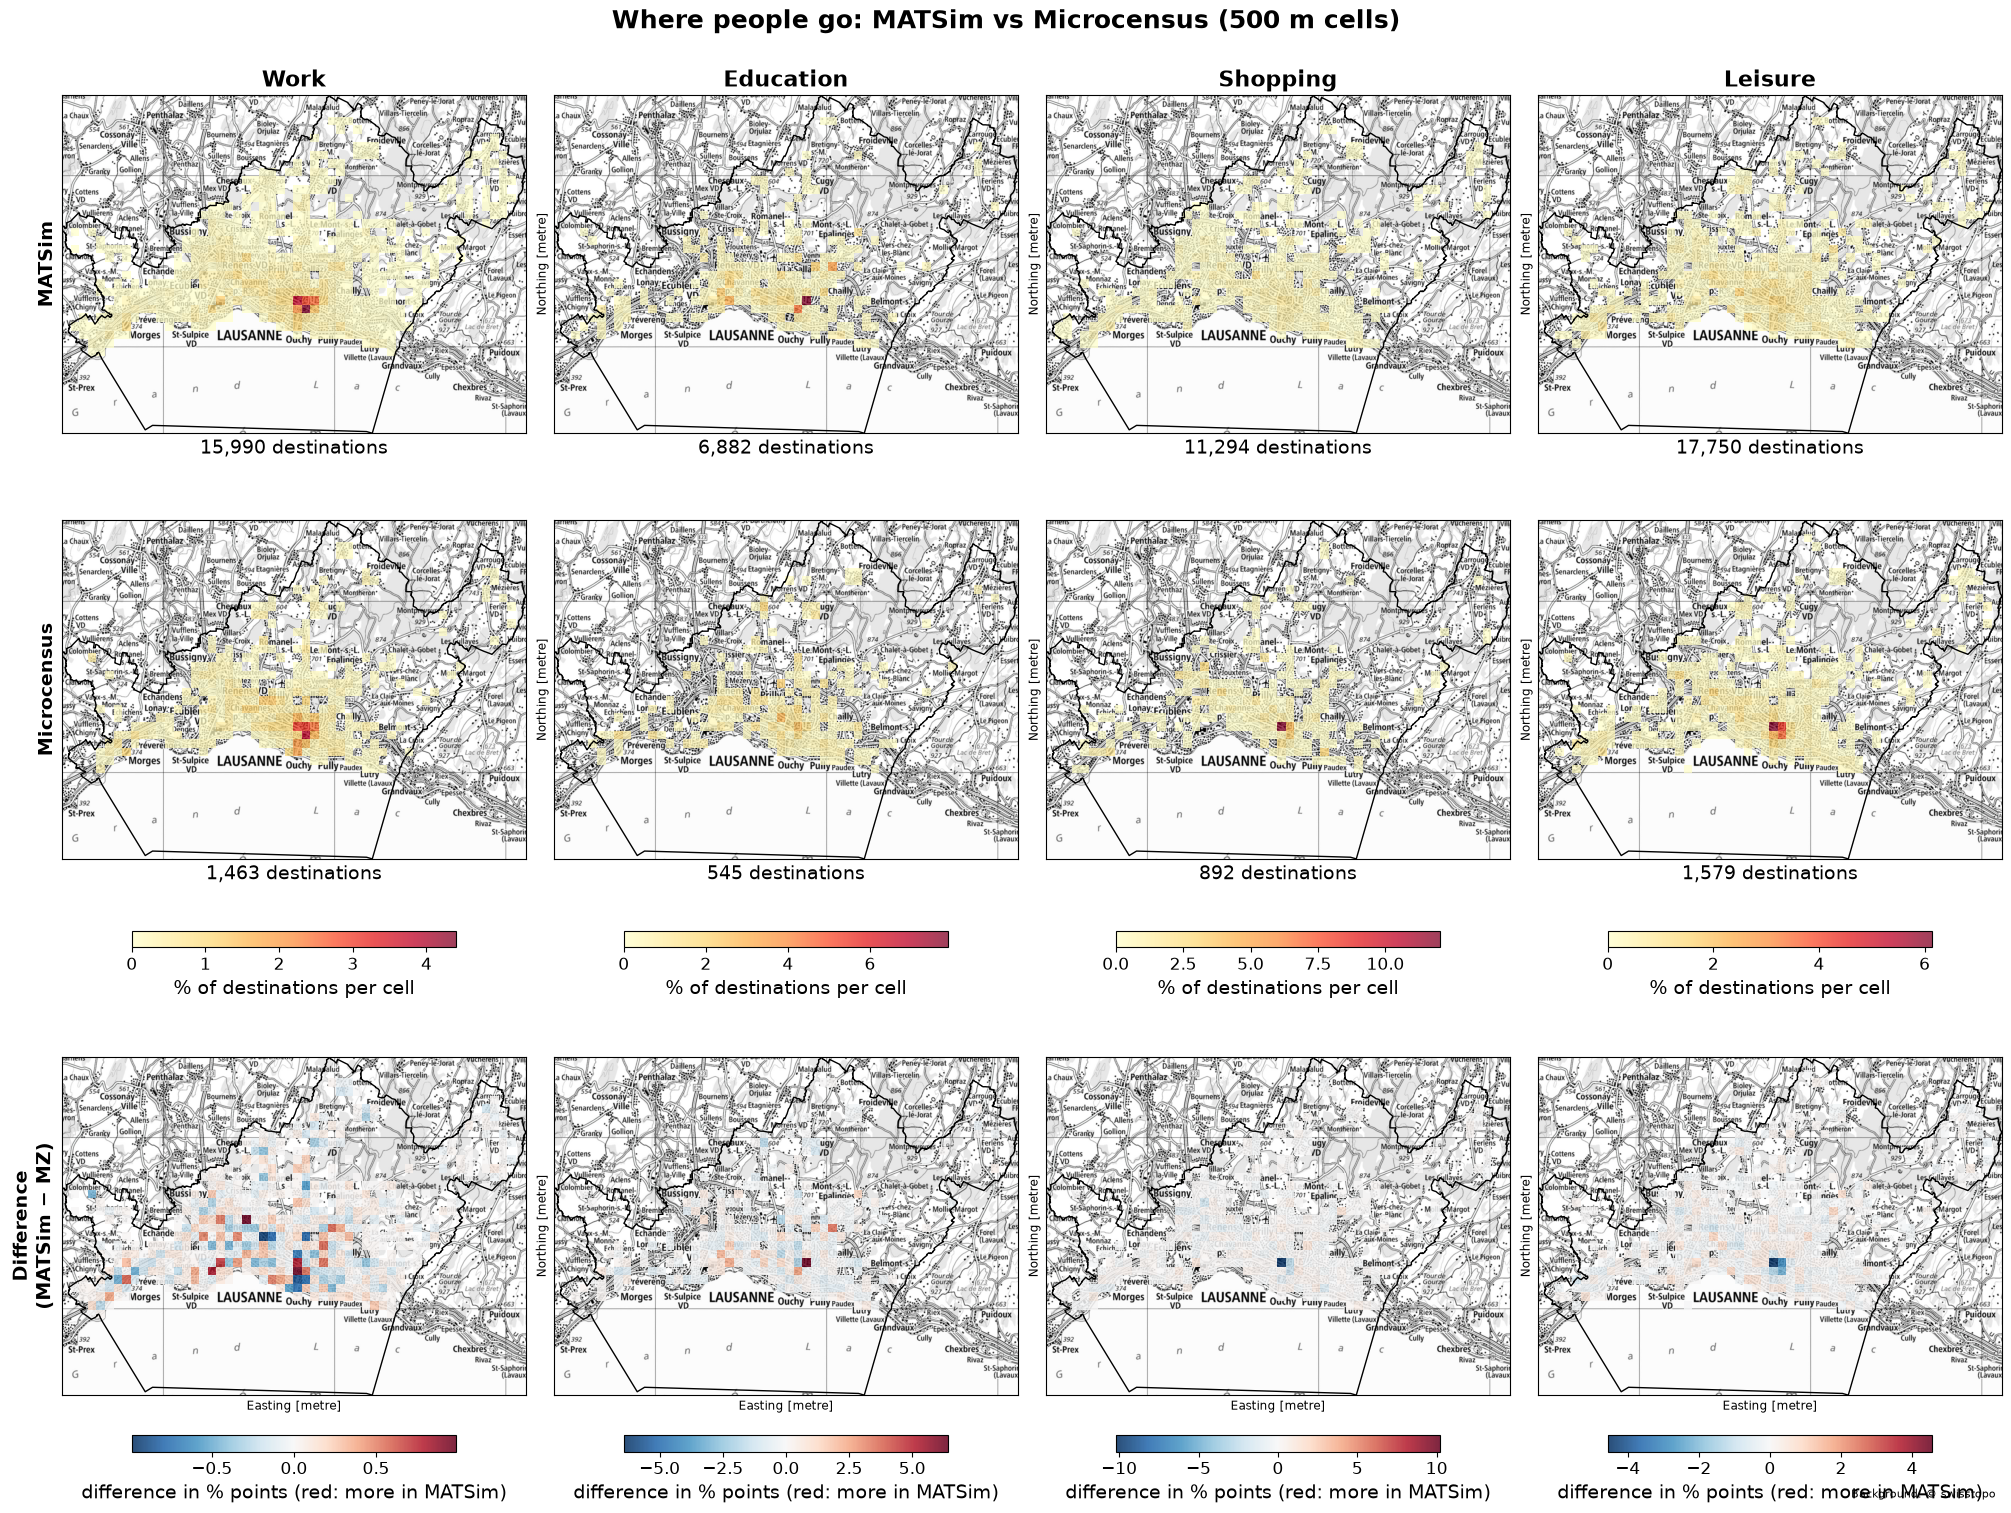

Saved destination_maps.png


In [9]:
"""
Destination maps: MATSim vs Swiss Microcensus (MZ) for the Lausanne study area.

2 x 4 grid (rows: MATSim | Microcensus, columns: work, education, shopping,
leisure) on a swisstopo background. Each cell shows the % of that purpose's
destinations that fall in each grid cell.
"""

import gzip
import xml.etree.ElementTree as ET

import contextily as ctx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely

# =============================================================================
# CONFIGURATION
# =============================================================================

# ---- paths ------------------------------------------------------------------
MATSIM_PLANS = r"working_rep\filterred_data\lausanne_population_filtered_age6plus.xml.gz"
MZ_TRIPS = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\wege.csv"
MZ_PERSONS = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\zielpersonen.csv"
MZ_HOUSEHOLDS_IN_AREA = r"working_rep\filterred_data\mz\household_ids_in_area.csv"
BOUNDARY_SHP = (r"C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\Lausanne_10pct"
                r"\Lausanne_10pct\Boundary\LausanneExtent.shp")
OUTPUT = "destination_maps.png"

# ---- microcensus columns (lower case) ---------------------------------------
HH_COL = "hhnr"          # household id
ORDER_COL = "f51100"     # trip order (negative = invalid)
PURPOSE_COL = "wzweck1"  # purpose of the trip's destination
WEIGHT_COL = "wp"        # weight
DEST_X_COL = "z_x"       # destination longitude (WGS84)
DEST_Y_COL = "z_y"       # destination latitude  (WGS84)
DAY_COL = "tag"          # 1 = Monday ... 7 = Sunday
KEEP_DAYS = {1, 2, 3, 4, 5}

# ---- maps -------------------------------------------------------------------
MATSIM_CRS = 2056        # Swiss LV95
MAP_CELL_M = 500         # grid cell size in metres
MAP_ZOOM = 13
SWISSTOPO_TILES = ("https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.pixelkarte-grau/"
                   "default/current/3857/{z}/{x}/{y}.jpeg")
MAP_PURPOSES = {"W": "Work", "E": "Education", "S": "Shopping", "L": "Leisure"}

# ---- activity / purpose -> letter -------------------------------------------
MZ_MAP = {
    1: "O", 2: "W", 3: "E", 4: "S", 5: "O", 6: "W",
    7: "O", 8: "L", 9: "O", 10: "O", 11: "H", 12: "O", 13: "O",
}
MATSIM_MAP = {
    "home": "H", "work": "W", "education": "E", "shop": "S", "leisure": "L",
    "other": "O", "outside": "Ou",
    "work_secondary": "W", "education_secondary": "E", "home_secondary": "O",
}


# =============================================================================
# HELPERS
# =============================================================================

def read_csv_clean(path: str) -> pd.DataFrame:
    """Read a CSV of unknown encoding/separator; lower-case the column names."""
    for encoding in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            candidates = [pd.read_csv(path, sep=sep, encoding=encoding, low_memory=False)
                          for sep in (",", ";", "\t")]
        except UnicodeDecodeError:
            continue
        df = max(candidates, key=lambda d: d.shape[1])
        df.columns = [str(c).strip().lower() for c in df.columns]
        return df
    raise ValueError(f"Could not decode {path}")


def study_area(crs: int):
    """Boundary GeoDataFrame and its merged polygon in the given CRS."""
    area = gpd.read_file(BOUNDARY_SHP).to_crs(epsg=crs)
    polygon = (area.geometry.union_all() if hasattr(area.geometry, "union_all")
               else area.unary_union)
    return area, polygon


# =============================================================================
# MATSIM DESTINATIONS
# =============================================================================

def matsim_destinations() -> pd.DataFrame:
    """Coordinates (LV95) of all work/education/shop/leisure activities."""
    rows = []
    with gzip.open(MATSIM_PLANS, "rb") as f:
        for _, el in ET.iterparse(f, events=("end",)):
            if el.tag != "person":
                continue
            plans = el.findall("plan")
            plan = next((p for p in plans if p.get("selected") == "yes"),
                        plans[0] if plans else None)
            if plan is not None:
                for act in plan.findall("activity"):
                    letter = MATSIM_MAP.get(act.get("type", ""))
                    x, y = act.get("x"), act.get("y")
                    if letter in MAP_PURPOSES and x and y:
                        rows.append((letter, float(x), float(y)))
            el.clear()
    df = pd.DataFrame(rows, columns=["purpose", "x", "y"])
    df["w"] = 1.0
    return df


# =============================================================================
# MICROCENSUS DESTINATIONS
# =============================================================================

def mz_destinations() -> pd.DataFrame:
    """Weekday MZ trips of area households ending inside the study area."""
    # households living in the area
    hh = read_csv_clean(MZ_HOUSEHOLDS_IN_AREA)
    ids = hh[HH_COL] if HH_COL in hh.columns else hh.iloc[:, 0]
    area_hh = set(pd.to_numeric(ids, errors="coerce").dropna())

    # keep only weekday target persons
    zp = read_csv_clean(MZ_PERSONS)
    for col in (HH_COL, DAY_COL):
        zp[col] = pd.to_numeric(zp[col], errors="coerce")
    zp = zp[zp[HH_COL].isin(area_hh) & zp[DAY_COL].isin(KEEP_DAYS)]
    hh_ids = set(zp[HH_COL].dropna())

    # trips of those households
    trips = read_csv_clean(MZ_TRIPS)
    for col in (HH_COL, WEIGHT_COL, ORDER_COL, PURPOSE_COL, DEST_X_COL, DEST_Y_COL):
        trips[col] = pd.to_numeric(trips[col], errors="coerce")
    trips = trips[trips[HH_COL].isin(hh_ids) & (trips[ORDER_COL] >= 0)]

    # keep trips with valid coordinates, a mapped purpose, and inside the area
    x, y = trips[DEST_X_COL], trips[DEST_Y_COL]
    purpose = trips[PURPOSE_COL].map(MZ_MAP)
    keep = x.notna() & y.notna() & purpose.isin(list(MAP_PURPOSES))

    pts = gpd.GeoSeries(gpd.points_from_xy(x[keep], y[keep]), crs=4326).to_crs(epsg=MATSIM_CRS)
    df = pd.DataFrame({"purpose": purpose[keep].to_numpy(),
                       "x": pts.x.to_numpy(), "y": pts.y.to_numpy(),
                       "w": trips.loc[keep, WEIGHT_COL].to_numpy()}).dropna()

    _, polygon = study_area(MATSIM_CRS)
    inside = shapely.contains_xy(polygon, df["x"].to_numpy(), df["y"].to_numpy())
    print(f"MZ destinations: {inside.sum()} inside area, {(~inside).sum()} outside (dropped)")
    return df[inside]


# =============================================================================
# PLOT
# =============================================================================

def plot_destination_maps(matsim: pd.DataFrame, mz: pd.DataFrame) -> None:
    area, polygon = study_area(MATSIM_CRS)
    minx, miny, maxx, maxy = area.total_bounds
    xedges = np.arange(minx, maxx + MAP_CELL_M, MAP_CELL_M)
    yedges = np.arange(miny, maxy + MAP_CELL_M, MAP_CELL_M)

    inside = shapely.contains_xy(polygon, matsim["x"].to_numpy(), matsim["y"].to_numpy())
    print(f"MATSim destinations: {inside.sum()} inside area, {(~inside).sum()} outside (dropped)")
    sources = {"MATSim": matsim[inside], "Microcensus": mz}

    fig, axes = plt.subplots(3, len(MAP_PURPOSES), figsize=(20, 15), layout="constrained")

    for j, (code, name) in enumerate(MAP_PURPOSES.items()):
        grids, totals = {}, {}
        for src, df in sources.items():
            d = df[df["purpose"] == code]
            h, _, _ = np.histogram2d(d["x"], d["y"], bins=[xedges, yedges], weights=d["w"])
            totals[src] = h.sum()
            grids[src] = 100 * h / h.sum() if h.sum() > 0 else h
        vmax = max(g.max() for g in grids.values())   # shared colour scale per column

        for i, src in enumerate(sources):
            ax = axes[i, j]
            mesh = ax.pcolormesh(xedges, yedges, np.ma.masked_equal(grids[src].T, 0),
                                 cmap="YlOrRd", vmin=0, vmax=vmax, alpha=0.75)
            area.boundary.plot(ax=ax, color="black", linewidth=1)
            ax.set_xlim(minx, maxx)
            ax.set_ylim(miny, maxy)
            ctx.add_basemap(ax, source=SWISSTOPO_TILES, crs=area.crs,
                            zoom=MAP_ZOOM, attribution=False)
            ax.set_aspect("equal")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xlabel(f"{totals[src]:,.0f} destinations", fontsize=14)
            if i == 0:
                ax.set_title(name, fontsize=16, fontweight="bold")
            if j == 0:
                ax.set_ylabel(src, fontsize=14, fontweight="bold")

        cbar = fig.colorbar(mesh, ax=axes[:2, j], shrink=0.7, location="bottom",
                            label="% of destinations per cell")
        cbar.ax.xaxis.label.set_size(14)       # label text
        cbar.ax.tick_params(labelsize=12)      # tick numbers

        # ---- third row: difference in percentage points (MATSim - Microcensus)
        diff = grids["MATSim"] - grids["Microcensus"]
        lim = np.abs(diff).max() or 1.0            # symmetric scale around 0
        ax = axes[2, j]
        dmesh = ax.pcolormesh(xedges, yedges, np.ma.masked_equal(diff.T, 0),
                              cmap="RdBu_r", vmin=-lim, vmax=lim, alpha=0.85)
        area.boundary.plot(ax=ax, color="black", linewidth=1)
        ax.set_xlim(minx, maxx)
        ax.set_ylim(miny, maxy)
        ctx.add_basemap(ax, source=SWISSTOPO_TILES, crs=area.crs,
                        zoom=MAP_ZOOM, attribution=False)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel("Difference\n(MATSim \u2212 MZ)", fontsize=14, fontweight="bold")
        cbar2 = fig.colorbar(dmesh, ax=ax, shrink=0.7, location="bottom",
                             label="difference in % points (red: more in MATSim)")
        cbar2.ax.xaxis.label.set_size(14)
        cbar2.ax.tick_params(labelsize=12)

    fig.suptitle(f"Where people go: MATSim vs Microcensus ({MAP_CELL_M} m cells)",
                 fontsize=18, fontweight="bold")
    fig.text(0.995, 0.005, "Background: \u00a9 swisstopo", ha="right", fontsize=8)
    fig.savefig(OUTPUT, dpi=200)
    plt.show()
    print("Saved", OUTPUT)


if __name__ == "__main__":
    plot_destination_maps(matsim_destinations(), mz_destinations())

MATSim persons: 3685 kept of 32766 (age 18-25)
MZ target persons kept after weekday + age filter: 122
MZ destinations: 335 inside area, 77 outside (dropped)
MATSim destinations: 6195 inside area, 0 outside (dropped)


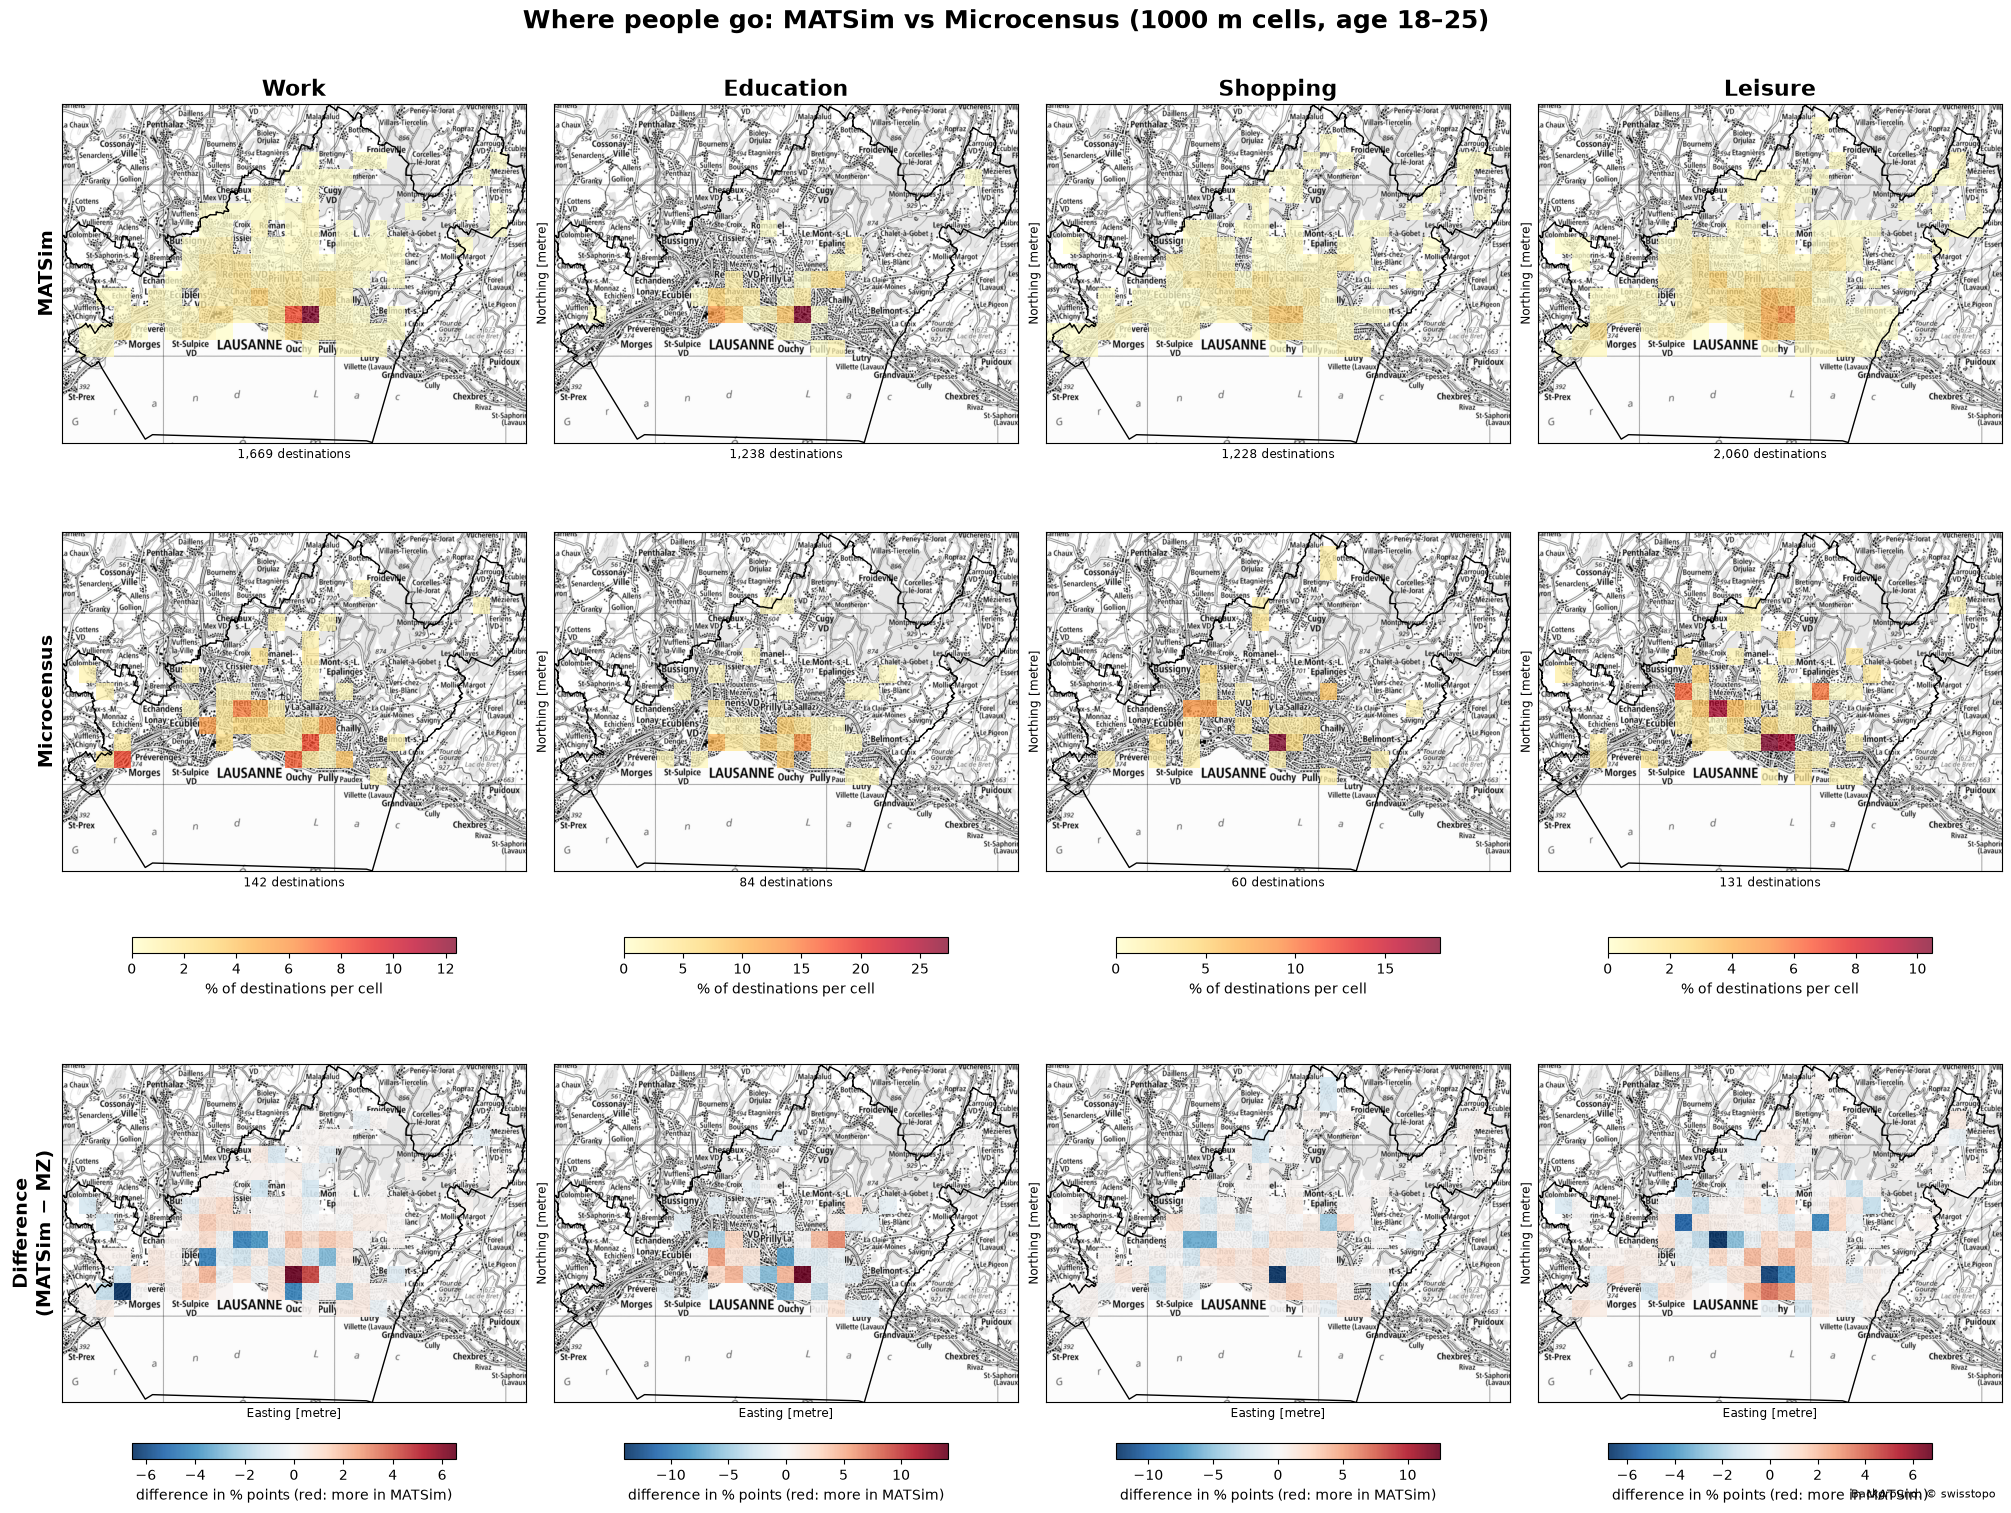

Saved destination_maps_age18_25_1000.png


In [8]:
"""
Destination maps: MATSim vs Swiss Microcensus (MZ) for the Lausanne study area.

2 x 4 grid (rows: MATSim | Microcensus, columns: work, education, shopping,
leisure) on a swisstopo background. Each cell shows the % of that purpose's
destinations that fall in each grid cell.
"""

import gzip
import xml.etree.ElementTree as ET

import contextily as ctx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely

# =============================================================================
# CONFIGURATION
# =============================================================================

# ---- paths ------------------------------------------------------------------
MATSIM_PLANS = r"working_rep\filterred_data\lausanne_population_filtered_age6plus.xml.gz"
MZ_TRIPS = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\wege.csv"
MZ_PERSONS = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\zielpersonen.csv"
MZ_HOUSEHOLDS_IN_AREA = r"working_rep\filterred_data\mz\household_ids_in_area.csv"
BOUNDARY_SHP = (r"C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\Lausanne_10pct"
                r"\Lausanne_10pct\Boundary\LausanneExtent.shp")
OUTPUT = "destination_maps_age18_25_1000.png"

# ---- microcensus columns (lower case) ---------------------------------------
HH_COL = "hhnr"          # household id
ORDER_COL = "f51100"     # trip order (negative = invalid)
PURPOSE_COL = "wzweck1"  # purpose of the trip's destination
WEIGHT_COL = "wp"        # weight
DEST_X_COL = "z_x"       # destination longitude (WGS84)
DEST_Y_COL = "z_y"       # destination latitude  (WGS84)
DAY_COL = "tag"          # 1 = Monday ... 7 = Sunday
KEEP_DAYS = {1, 2, 3, 4, 5}

# ---- age filter (inclusive; set both to None to disable) ---------------------
MIN_AGE = 18
MAX_AGE = 25
MZ_AGE_COL = "alter"         # age column in zielpersonen.csv
MATSIM_AGE_ATTR = "age"      # <attribute name="age"> in the plans file

# ---- maps -------------------------------------------------------------------
MATSIM_CRS = 2056        # Swiss LV95
MAP_CELL_M = 1000         # grid cell size in metres
MAP_ZOOM = 13
SWISSTOPO_TILES = ("https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.pixelkarte-grau/"
                   "default/current/3857/{z}/{x}/{y}.jpeg")
MAP_PURPOSES = {"W": "Work", "E": "Education", "S": "Shopping", "L": "Leisure"}

# ---- activity / purpose -> letter -------------------------------------------
MZ_MAP = {
    1: "O", 2: "W", 3: "E", 4: "S", 5: "O", 6: "W",
    7: "O", 8: "L", 9: "O", 10: "O", 11: "H", 12: "O", 13: "O",
}
MATSIM_MAP = {
    "home": "H", "work": "W", "education": "E", "shop": "S", "leisure": "L",
    "other": "O", "outside": "Ou",
    "work_secondary": "W", "education_secondary": "E", "home_secondary": "O",
}


# =============================================================================
# HELPERS
# =============================================================================

def read_csv_clean(path: str) -> pd.DataFrame:
    """Read a CSV of unknown encoding/separator; lower-case the column names."""
    for encoding in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            candidates = [pd.read_csv(path, sep=sep, encoding=encoding, low_memory=False)
                          for sep in (",", ";", "\t")]
        except UnicodeDecodeError:
            continue
        df = max(candidates, key=lambda d: d.shape[1])
        df.columns = [str(c).strip().lower() for c in df.columns]
        return df
    raise ValueError(f"Could not decode {path}")


def study_area(crs: int):
    """Boundary GeoDataFrame and its merged polygon in the given CRS."""
    area = gpd.read_file(BOUNDARY_SHP).to_crs(epsg=crs)
    polygon = (area.geometry.union_all() if hasattr(area.geometry, "union_all")
               else area.unary_union)
    return area, polygon


# =============================================================================
# MATSIM DESTINATIONS
# =============================================================================

def age_ok(age) -> bool:
    """True if the age lies in [MIN_AGE, MAX_AGE] (always True if no filter set)."""
    if MIN_AGE is None and MAX_AGE is None:
        return True
    if age is None or pd.isna(age):
        return False
    return (MIN_AGE is None or age >= MIN_AGE) and (MAX_AGE is None or age <= MAX_AGE)


def matsim_person_age(person_el):
    """Age from the person's <attribute name="age"> (None if absent)."""
    attrs = person_el.find("attributes")
    if attrs is not None:
        for a in attrs.findall("attribute"):
            if a.get("name") == MATSIM_AGE_ATTR:
                try:
                    return float((a.text or "").strip())
                except ValueError:
                    return None
    return None


def matsim_destinations() -> pd.DataFrame:
    """Coordinates (LV95) of all work/education/shop/leisure activities."""
    rows = []
    n_persons = n_kept = 0
    with gzip.open(MATSIM_PLANS, "rb") as f:
        for _, el in ET.iterparse(f, events=("end",)):
            if el.tag != "person":
                continue
            n_persons += 1
            if not age_ok(matsim_person_age(el)):
                el.clear()
                continue
            n_kept += 1
            plans = el.findall("plan")
            plan = next((p for p in plans if p.get("selected") == "yes"),
                        plans[0] if plans else None)
            if plan is not None:
                for act in plan.findall("activity"):
                    letter = MATSIM_MAP.get(act.get("type", ""))
                    x, y = act.get("x"), act.get("y")
                    if letter in MAP_PURPOSES and x and y:
                        rows.append((letter, float(x), float(y)))
            el.clear()
    print(f"MATSim persons: {n_kept} kept of {n_persons} (age {MIN_AGE}-{MAX_AGE})")
    df = pd.DataFrame(rows, columns=["purpose", "x", "y"])
    df["w"] = 1.0
    return df


# =============================================================================
# MICROCENSUS DESTINATIONS
# =============================================================================

def mz_destinations() -> pd.DataFrame:
    """Weekday MZ trips of area households ending inside the study area."""
    # households living in the area
    hh = read_csv_clean(MZ_HOUSEHOLDS_IN_AREA)
    ids = hh[HH_COL] if HH_COL in hh.columns else hh.iloc[:, 0]
    area_hh = set(pd.to_numeric(ids, errors="coerce").dropna())

    # keep only weekday target persons
    zp = read_csv_clean(MZ_PERSONS)
    for col in (HH_COL, DAY_COL):
        zp[col] = pd.to_numeric(zp[col], errors="coerce")
    zp = zp[zp[HH_COL].isin(area_hh) & zp[DAY_COL].isin(KEEP_DAYS)]
    if MIN_AGE is not None or MAX_AGE is not None:
        if MZ_AGE_COL not in zp.columns:
            raise SystemExit(f"Age column '{MZ_AGE_COL}' not in zielpersonen. "
                             f"Available: {list(zp.columns)}")
        age = pd.to_numeric(zp[MZ_AGE_COL], errors="coerce")
        zp = zp[age.map(age_ok)]
    hh_ids = set(zp[HH_COL].dropna())
    print(f"MZ target persons kept after weekday + age filter: {len(hh_ids)}")

    # trips of those households
    trips = read_csv_clean(MZ_TRIPS)
    for col in (HH_COL, WEIGHT_COL, ORDER_COL, PURPOSE_COL, DEST_X_COL, DEST_Y_COL):
        trips[col] = pd.to_numeric(trips[col], errors="coerce")
    trips = trips[trips[HH_COL].isin(hh_ids) & (trips[ORDER_COL] >= 0)]

    # keep trips with valid coordinates, a mapped purpose, and inside the area
    x, y = trips[DEST_X_COL], trips[DEST_Y_COL]
    purpose = trips[PURPOSE_COL].map(MZ_MAP)
    keep = x.notna() & y.notna() & purpose.isin(list(MAP_PURPOSES))

    pts = gpd.GeoSeries(gpd.points_from_xy(x[keep], y[keep]), crs=4326).to_crs(epsg=MATSIM_CRS)
    df = pd.DataFrame({"purpose": purpose[keep].to_numpy(),
                       "x": pts.x.to_numpy(), "y": pts.y.to_numpy(),
                       "w": trips.loc[keep, WEIGHT_COL].to_numpy()}).dropna()

    _, polygon = study_area(MATSIM_CRS)
    inside = shapely.contains_xy(polygon, df["x"].to_numpy(), df["y"].to_numpy())
    print(f"MZ destinations: {inside.sum()} inside area, {(~inside).sum()} outside (dropped)")
    return df[inside]


# =============================================================================
# PLOT
# =============================================================================

def plot_destination_maps(matsim: pd.DataFrame, mz: pd.DataFrame) -> None:
    area, polygon = study_area(MATSIM_CRS)
    minx, miny, maxx, maxy = area.total_bounds
    xedges = np.arange(minx, maxx + MAP_CELL_M, MAP_CELL_M)
    yedges = np.arange(miny, maxy + MAP_CELL_M, MAP_CELL_M)

    inside = shapely.contains_xy(polygon, matsim["x"].to_numpy(), matsim["y"].to_numpy())
    print(f"MATSim destinations: {inside.sum()} inside area, {(~inside).sum()} outside (dropped)")
    sources = {"MATSim": matsim[inside], "Microcensus": mz}

    fig, axes = plt.subplots(3, len(MAP_PURPOSES), figsize=(20, 15), layout="constrained")

    for j, (code, name) in enumerate(MAP_PURPOSES.items()):
        grids, totals = {}, {}
        for src, df in sources.items():
            d = df[df["purpose"] == code]
            h, _, _ = np.histogram2d(d["x"], d["y"], bins=[xedges, yedges], weights=d["w"])
            totals[src] = h.sum()
            grids[src] = 100 * h / h.sum() if h.sum() > 0 else h
        vmax = max(g.max() for g in grids.values())   # shared colour scale per column

        for i, src in enumerate(sources):
            ax = axes[i, j]
            mesh = ax.pcolormesh(xedges, yedges, np.ma.masked_equal(grids[src].T, 0),
                                 cmap="YlOrRd", vmin=0, vmax=vmax, alpha=0.75)
            area.boundary.plot(ax=ax, color="black", linewidth=1)
            ax.set_xlim(minx, maxx)
            ax.set_ylim(miny, maxy)
            ctx.add_basemap(ax, source=SWISSTOPO_TILES, crs=area.crs,
                            zoom=MAP_ZOOM, attribution=False)
            ax.set_aspect("equal")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xlabel(f"{totals[src]:,.0f} destinations")
            if i == 0:
                ax.set_title(name, fontsize=16, fontweight="bold")
            if j == 0:
                ax.set_ylabel(src, fontsize=14, fontweight="bold")
        fig.colorbar(mesh, ax=axes[:2, j], shrink=0.7, location="bottom",
                     label="% of destinations per cell")

        # ---- third row: difference in percentage points (MATSim - Microcensus)
        diff = grids["MATSim"] - grids["Microcensus"]
        lim = np.abs(diff).max() or 1.0            # symmetric scale around 0
        ax = axes[2, j]
        dmesh = ax.pcolormesh(xedges, yedges, np.ma.masked_equal(diff.T, 0),
                              cmap="RdBu_r", vmin=-lim, vmax=lim, alpha=0.9)
        area.boundary.plot(ax=ax, color="black", linewidth=1)
        ax.set_xlim(minx, maxx)
        ax.set_ylim(miny, maxy)
        ctx.add_basemap(ax, source=SWISSTOPO_TILES, crs=area.crs,
                        zoom=MAP_ZOOM, attribution=False)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel("Difference\n(MATSim \u2212 MZ)", fontsize=14, fontweight="bold")
        fig.colorbar(dmesh, ax=ax, shrink=0.7, location="bottom",
                     label="difference in % points (red: more in MATSim)")

    age_label = (f", age {MIN_AGE}\u2013{MAX_AGE}"
                 if MIN_AGE is not None or MAX_AGE is not None else "")
    fig.suptitle(f"Where people go: MATSim vs Microcensus ({MAP_CELL_M} m cells{age_label})",
                 fontsize=18, fontweight="bold")
    fig.text(0.995, 0.005, "Background: \u00a9 swisstopo", ha="right", fontsize=8)
    fig.savefig(OUTPUT, dpi=200)
    plt.show()
    print("Saved", OUTPUT)


if __name__ == "__main__":
    plot_destination_maps(matsim_destinations(), mz_destinations())